# Tugas Kelompok 2: Implementasi Sistem Pengumpulan Data dan Exploratory Data Analysis (X / Twitter)

## Kelompok

1. Erland Hafizh Aristovi (2306165686)
2. Jasmine Rakhaila (2306165774)
3. Leonita Cecilia (2306165710)
4. Yeshua Marco Gracia Manurung (2306210286)

## Gambaran Umum

**Topik (TK-1):** Analisis kekhawatiran publik terhadap kebersihan dan keamanan pangan Program Makan Bergizi Gratis (MBG) pada YouTube dan X.

Notebook ini mencakup **pengumpulan data X melalui web scraping** (kata kunci dan hashtag; bagian 1) dan **Exploratory Data Analysis** atas raw dataset hasilnya (bagian 2). Pre-processing, normalisasi, dan penggabungan dengan data YouTube dilakukan pada tahap berikutnya. Data YouTube dikumpulkan terpisah melalui YouTube Data API.

| Pertanyaan penelitian (TK-1) | Data X yang dibutuhkan | Kolom di dataset |
|---|---|---|
| RQ1: jenis permasalahan keamanan/kebersihan makanan | teks unggahan (tweet, reply, quote) | `text`, `lang` |
| RQ2: variasi permasalahan antarwilayah | teks yang menyebut lokasi dan waktu unggah | `text`, `created_at` |
| RQ3: kekhawatiran/keluhan publik | teks dan engagement | `text`, `reply_count`, `repost_count`, `like_count`, `quote_count` |

### Skema dataset mentah

| Field | Tipe | Catatan |
|---|---|---|
| `post_id` | string | wajib string; ID tweet panjang dan rusak jika dibaca sebagai angka |
| `text` | string | teks unggahan |
| `created_at` | string ISO 8601 (UTC) | contoh `2026-01-23T02:42:27Z` |
| `author_handle` | string | handle tanpa `@`; **di-hash saat normalisasi** (tahap berikutnya) |
| `reply_count`, `repost_count`, `like_count`, `quote_count` | integer / null | teks seperti `1,2 rb` atau `1.2K` di-parse menjadi angka; `null` jika tidak tersedia |
| `is_reply`, `parent_post_id` | bool, string / null | `parent_post_id` hanya terisi jika `is_reply = True` dan induknya terbaca |
| `url` | string | tautan ke unggahan |
| `query_id`, `window_start`, `window_end` | string | jejak (traceability): query dan jendela waktu yang pertama kali menemukan unggahan |
| `collected_at` | string | waktu pengambilan (ISO 8601, UTC) |

Kolom tambahan (di luar skema wajib): `lang`, `view_count`, `text_truncated`, `is_quote`, `quoted_post_url`, `matched_query_ids`, `n_matched_searches`.

### Alur pipeline

```
Parameter (query, periode) -> Login manual sekali (simpan sesi) -> Scraping hasil pencarian X (Playwright)
-> Simpan observasi mentah (JSONL, append) -> Deduplikasi per post_id -> Raw dataset (CSV) + metadata run
-> Exploratory Data Analysis (bagian 2)
-> Exploratory Data Analysis (bagian 2)
-> Exploratory Data Analysis (bagian 2)
-> Exploratory Data Analysis (bagian 2)
```

### Cara menjalankan

1. Jalankan sel **1.1** (pemasangan `playwright` dan `pandas`, serta Chromium).
2. Biarkan `SMOKE_TEST = True` pada **1.2** untuk uji cepat (1 pencarian, 20 unggahan). Ubah ke `False` untuk pengumpulan penuh.
3. Pada run pertama, sel **1.3** membuka jendela Chrome. Login ke X **secara manual** dengan email/username + password (bukan *Sign in with Google*), lalu tekan Enter di notebook. Sesi disimpan di `.auth/x_state.json`; password tidak pernah disimpan di kode.
4. Jalankan sel **1.8**. Proses bisa dihentikan dan dilanjutkan karena pencarian yang sudah selesai dilewati.
5. Jalankan sel penyusunan dataset dan validasi di **1.8** dan **1.9**.
6. Jalankan bagian **2** (EDA). Bagian ini hanya membaca file di `data/raw/x`, sehingga bisa dijalankan tanpa mengulang bagian 1.

> **Catatan penting**
> - Gunakan akun X khusus (bukan akun utama). Scraping dapat melanggar Ketentuan Layanan X dan berisiko membuat akun dibatasi. Bahas pada bagian C5 dan C6 laporan.
> - Folder `.auth/` (sesi login) dan `data/raw/x*/` berisi data sensitif dan **tidak boleh di-commit** (sudah dimasukkan ke `.gitignore`).
> - Struktur DOM X sering berubah. Jika pencarian mengembalikan 0 unggahan padahal login berhasil, periksa selector pada `EXTRACT_JS` (bagian 1.5).

# 1. Pengumpulan Data

## 1.1. Import Library

Memasang dan mengimpor library yang dibutuhkan, yaitu:

* `playwright` untuk mengendalikan browser (Chromium) dan membaca DOM halaman pencarian X.
* `pandas` untuk menyusun dan menyimpan dataset dalam bentuk tabel (DataFrame).
* `asyncio` dan `random` untuk jeda antar-aksi (menghindari rate limit) dan pengaturan retry.
* `json`, `hashlib`, `re`, dan `datetime` untuk penyimpanan JSONL, ID pencarian, parsing angka, dan normalisasi waktu.

Sel pemasangan aman dijalankan ulang.

In [2]:
# Pasang dependensi dan browser
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "playwright", "pandas"], check=True)
subprocess.run([sys.executable, "-m", "playwright", "install", "chromium"], check=True)

CompletedProcess(args=['/usr/local/bin/python3', '-m', 'playwright', 'install', 'chromium'], returncode=0)

In [3]:
import asyncio
import getpass
import hashlib
import html
import json
import random
import re
import sys
from datetime import date, datetime, timedelta, timezone
from importlib.metadata import version
from pathlib import Path
from urllib.parse import quote

import pandas as pd
from playwright.async_api import async_playwright

## 1.2. Parameter Pengumpulan

Semua parameter pengumpulan dikumpulkan dalam satu sel agar mudah dicatat di laporan (C3) dan direproduksi:

* `SMOKE_TEST`: `True` untuk uji cepat (1 pencarian, 20 unggahan), `False` untuk pengumpulan penuh.
* **Periode** (`START_DATE` sampai `END_DATE`, `END_DATE` eksklusif, dalam **UTC**) dipecah menjadi jendela waktu awal sepanjang `WINDOW_DAYS`.
* **Pemecahan jendela adaptif** (`ADAPTIVE_SPLIT`): tab *Latest* mengurutkan dari yang terbaru, sehingga jendela yang padat hanya terambil bagian akhirnya saja. Jika sebuah pencarian mencapai `MAX_POSTS_PER_SEARCH`, jendelanya dibelah dua dan dicari ulang, sampai selebar `MIN_WINDOW_HOURS`. Dengan cara ini sebaran waktu merata tanpa harus memakai jendela kecil untuk semua query. Jendela terkecil yang tetap penuh dicatat sebagai `saturated`. `MAX_SEARCHES_PER_RUN` membatasi jumlah pencarian dalam satu run (jalankan lagi untuk melanjutkan).
* **Mode isi celah** (`FILL_GAPS`, `GAP_START`, `GAP_END`) dan **prioritas query** (`PRIORITY_QUERIES`): dipakai setelah pengumpulan awal untuk menambal bagian periode yang belum tercakup (pencarian `error`, atau jendela yang tidak pernah dijalankan). Dengan `FILL_GAPS = True`, jendela dihitung dari `x_search_log.jsonl`, bukan dari `START_DATE`/`END_DATE`. `PRIORITY_QUERIES` menentukan query mana yang dijalankan dan urutannya (kosong = semua query).
* **Batas dan jeda**: jumlah unggahan per pencarian, jumlah scroll tanpa hasil baru sebelum berhenti, jeda acak antar-scroll dan antar-pencarian, jumlah retry, dan lama tidur saat terkena rate limit.
* **Lokasi file**: seluruh keluaran berada di `data/raw/x` (atau `data/raw/x_smoke` saat uji cepat) pada root repository.

In [4]:
# --- Mode ---
SMOKE_TEST = False  # True: uji cepat. False: pengumpulan penuh.
HEADLESS = True  # Login pertama selalu memakai jendela browser terlihat.

# --- Periode (END_DATE eksklusif) ---
START_DATE = date(2025, 9, 28)
END_DATE = date(2025, 11, 27)
WINDOW_DAYS = 30
LANG = "in"  # X memakai kode "in" (bukan "id") untuk Bahasa Indonesia pada pencarian; "" untuk menonaktifkan

# --- Pemecahan jendela adaptif ---
ADAPTIVE_SPLIT = not SMOKE_TEST  # belah jendela yang mencapai MAX_POSTS_PER_SEARCH
MIN_WINDOW_HOURS = 6  # jendela terkecil; makin kecil makin lengkap, tetapi makin banyak pencarian
MAX_SEARCHES_PER_RUN = 100  # pengaman: run berhenti rapi setelah N pencarian, jalankan lagi untuk melanjutkan

# --- Mode isi celah dan prioritas query (opsional; lihat bagian 1.4) ---
FILL_GAPS = True  # True: hanya cari jendela GAP_START-GAP_END yang belum tercakup menurut log. False: seluruh START_DATE-END_DATE
GAP_START = date(2025, 9, 28)
GAP_END = date(2025, 11, 27)  # eksklusif
# Urutan query yang dijalankan (query pertama diselesaikan lebih dulu). Kosong = semua query.
PRIORITY_QUERIES = [
    "kw_benda_asing", "kw_bakteri", "kw_basi", "kw_kualitas", "kw_keracunan", "kw_higiene",
]

# --- Batas dan jeda ---
MAX_POSTS_PER_SEARCH = 20 if SMOKE_TEST else 100
MAX_STALE_SCROLLS = 5  # berhenti jika N kali scroll berturut-turut tidak menambah unggahan baru
SCROLL_DELAY = (1.5, 3.0)  # detik, acak
SEARCH_DELAY = (10.0, 8.0)  # detik, jeda antar-pencarian
MAX_RETRIES = 3
RATE_LIMIT_SLEEP = 300  # detik, jeda jika terkena rate limit

# --- Browser ---
CONTEXT_OPTIONS = {
    "locale": "id-ID",
    "timezone_id": "Asia/Jakarta",
    "viewport": {"width": 1280, "height": 1600},  # viewport tinggi: lebih banyak unggahan termuat per layar
}

# --- Lokasi file (relatif terhadap root repository) ---
BASE_DIR = Path.cwd().parent if Path.cwd().name == "x" else Path.cwd()
RUN_NAME = "x_smoke" if SMOKE_TEST else "x"
OUT_DIR = BASE_DIR / "data" / "raw" / RUN_NAME
AUTH_DIR = BASE_DIR / ".auth"
STATE_PATH = AUTH_DIR / "x_state.json"  # sesi login (cookie); jangan di-commit
OBS_PATH = OUT_DIR / "x_observations.jsonl"  # semua hasil mentah per pencarian (append-only)
LOG_PATH = OUT_DIR / "x_search_log.jsonl"  # status tiap pencarian, untuk resume
DATASET_PATH = OUT_DIR / "x_raw_dataset.csv"  # raw dataset hasil deduplikasi
META_PATH = OUT_DIR / "x_run_metadata.json"

OUT_DIR.mkdir(parents=True, exist_ok=True)
AUTH_DIR.mkdir(parents=True, exist_ok=True)

## 1.3. Sesi Login X

X tidak menyediakan API gratis untuk pencarian, dan halaman pencarian hanya dapat dibuka setelah login. Sebagai pengganti API key, pipeline memakai **sesi login (cookie)** yang disimpan di `.auth/x_state.json` dan dipakai ulang pada run berikutnya. Ada dua cara (`LOGIN_METHOD`):

* **`"browser"` (default)**: Google Chrome terbuka, lalu login manual ke X. Setelah timeline muncul, kembali ke notebook dan tekan Enter. Gunakan email/username + password X, bukan *Sign in with Google* yang sering ditolak pada browser otomatis.
* **`"cookie"` (cadangan)**: jika login di jendela otomatis tetap gagal. Login ke x.com di browser biasa, buka DevTools (Application, Cookies, `https://x.com`), lalu salin nilai `auth_token` dan `ct0` saat diminta. Nilai ini setara password sesi: jangan dibagikan atau di-commit.

Sel ini memeriksa bahwa file sesi benar-benar berisi cookie login X (`auth_token` dan `ct0`). Sesi yang hanya berisi cookie Google (login belum selesai atau memakai *Sign in with Google*) dihapus dan ditolak dengan pesan jelas. Sel ini tidak pernah mencetak nilai cookie.

In [25]:
LOGIN_METHOD = "browser"  # "browser" atau "cookie"
CHROME_PROFILE = AUTH_DIR / "chrome_profile"  # profil browser khusus notebook ini; jangan di-commit


async def login_with_browser():
    launch_args = dict(
        user_data_dir=str(CHROME_PROFILE),
        headless=False,
        ignore_default_args=["--enable-automation"],
        args=["--disable-blink-features=AutomationControlled"],
        **CONTEXT_OPTIONS,
    )
    async with async_playwright() as p:
        try:
            context = await p.chromium.launch_persistent_context(channel="chrome", **launch_args)
        except Exception:  # Google Chrome tidak terpasang: pakai Chromium bawaan Playwright
            context = await p.chromium.launch_persistent_context(**launch_args)
        page = context.pages[0] if context.pages else await context.new_page()
        await page.goto("https://x.com/i/flow/login")
        input("Login ke X di jendela browser sampai timeline muncul, lalu tekan Enter di sini...")
        await context.storage_state(path=str(STATE_PATH))
        await context.close()


def login_with_cookies():
    auth_token = getpass.getpass("Nilai cookie auth_token: ").strip()
    ct0 = getpass.getpass("Nilai cookie ct0: ").strip()
    cookies = [
        {"name": name, "value": value, "domain": ".x.com", "path": "/", "expires": -1,
         "httpOnly": http_only, "secure": True, "sameSite": "None"}
        for name, value, http_only in (("auth_token", auth_token, True), ("ct0", ct0, False))
    ]
    STATE_PATH.write_text(json.dumps({"cookies": cookies, "origins": []}), encoding="utf-8")


def session_is_valid():
    """Sesi X sah hanya jika cookie auth_token dan ct0 milik x.com/twitter.com ada."""
    if not STATE_PATH.exists():
        return False
    try:
        cookies = json.loads(STATE_PATH.read_text(encoding="utf-8")).get("cookies", [])
    except json.JSONDecodeError:
        return False
    names = {c["name"] for c in cookies if any(d in c.get("domain", "") for d in ("x.com", "twitter.com"))}
    return {"auth_token", "ct0"} <= names


if STATE_PATH.exists() and not session_is_valid():
    print("Sesi lama tidak berisi cookie login X (auth_token/ct0), sehingga dihapus dan login diulang.")
    STATE_PATH.unlink()

if not STATE_PATH.exists():
    if LOGIN_METHOD == "cookie":
        login_with_cookies()
    else:
        await login_with_browser()

if not session_is_valid():
    STATE_PATH.unlink(missing_ok=True)
    raise RuntimeError(
        "Login X belum selesai: cookie auth_token/ct0 tidak ditemukan. Pastikan timeline X (x.com/home) sudah "
        "tampil sebelum menekan Enter, dan login memakai email/username + password X (bukan Sign in with Google). "
        "Jalankan sel ini lagi, atau pakai LOGIN_METHOD = \"cookie\"."
    )
print(f"Sesi login X valid: {STATE_PATH}")

Sesi login X valid: /Users/macbookair/Documents/TK Anmedsos/mbg-social-analytics/.auth/x_state.json


## 1.4. Query Pencarian

Mendefinisikan query yang dipakai pada pencarian X, dalam dua kelompok:

* **Kata kunci** (`KEYWORD_QUERIES`): dipetakan ke jenis permasalahan pada TK-1, yaitu keracunan, makanan basi, kontaminasi bakteri, benda/organisme asing, kebersihan, dan kualitas makanan.
* **Hashtag** (`HASHTAG_QUERIES`): lebih luas, dengan penyaringan relevansi dilakukan pada tahap pre-processing.

Setiap query ditempelkan operator pencarian X: `lang:`, `since_time:`, `until_time:`, dan `-filter:retweets`. Jendela waktu memakai operator berbasis **epoch UTC** (`since_time`/`until_time`) dan berlaku sebagai `[window_start, window_end)`. Operator `since:`/`until:` sengaja tidak dipakai: pada uji coba, operator itu dihitung per hari menurut zona waktu lokal akun (WIB) dan `until` bersifat inklusif, sehingga jendela saling tumpang tindih dan batasnya tidak sama dengan `created_at` (UTC). Karena presisinya sampai detik, jendela juga bisa dipecah sampai level jam. Satu **pencarian** = satu query x satu jendela waktu. Setiap pencarian punya `search_id` yang memuat hash query, sehingga:

* pencarian yang sudah selesai dilewati saat run dilanjutkan, dan
* pencarian diulang otomatis jika string query berubah.

Kunci dictionary menjadi `query_id` pada dataset akhir.

`split_search()` membelah satu pencarian menjadi dua pencarian dengan jendela separuh lebarnya. Fungsi ini dipakai pada bagian 1.8 saat sebuah pencarian mencapai batas unggahan (pemecahan jendela adaptif).
**Mode isi celah dan prioritas.** `load_covered()` membaca `x_search_log.jsonl` dan mengumpulkan interval waktu yang sudah tercakup per query (status akhir `ok` atau `no_results`; pencarian `split` dihitung lewat anak-anaknya). `find_gaps()` mengurangkan interval itu dari rentang `GAP_START`-`GAP_END`, dan `build_gap_searches()` membuat pencarian hanya untuk sisanya, dengan urutan mengikuti `PRIORITY_QUERIES`. Cara ini menjangkau pencarian `error` dan jendela yang tidak pernah dijalankan (misalnya karena grid jendela berbeda antar-run) tanpa mengulang yang sudah selesai. Jalankan ulang sel ini setelah pengumpulan untuk menghitung celah yang tersisa. Jendela terkecil yang sudah `ok` tetapi penuh (`saturated`) dianggap tercakup dan tidak dicari ulang.


In [5]:
# --- Query: kata kunci ---
MBG = '("makan bergizi gratis" OR MBG)'
KEYWORD_QUERIES = {
    "kw_keracunan": f"{MBG} keracunan",
    "kw_basi": f'{MBG} (basi OR bau OR "tidak layak" OR berlendir)',
    "kw_bakteri": f'{MBG} (bakteri OR kontaminasi OR salmonella OR "e. coli")',
    "kw_benda_asing": f'{MBG} (belatung OR ulat OR kecoa OR "benda asing" OR rambut OR plastik)',
    "kw_higiene": f'{MBG} (higienis OR kebersihan OR sanitasi OR SPPG)',
    "kw_kualitas": f'{MBG} (kualitas OR mentah OR hambar OR "tidak matang")',
}

# --- Query: hashtag ---
HASHTAG_QUERIES = {
    "ht_mbg": "#MBG",
    "ht_makanbergizigratis": "#MakanBergiziGratis",
    "ht_keracunanmbg": "#KeracunanMBG",
    "ht_mbgkeracunan": "#MBGKeracunan",
    "ht_mbgbasi": "#MBGBasi",
}


def utc_midnight(d):
    return datetime(d.year, d.month, d.day, tzinfo=timezone.utc)


def iso_utc(dt):
    return dt.astimezone(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def from_iso_utc(value):
    return datetime.fromisoformat(value.replace("Z", "+00:00"))


def build_windows(start, end, days):
    windows, cur, stop = [], utc_midnight(start), utc_midnight(end)
    while cur < stop:
        nxt = min(cur + timedelta(days=days), stop)
        windows.append((cur, nxt))
        cur = nxt
    return windows


def build_query(base, since, until, lang=LANG):
    parts = [base]
    if lang:
        parts.append(f"lang:{lang}")
    parts += [f"since_time:{int(since.timestamp())}", f"until_time:{int(until.timestamp())}", "-filter:retweets"]
    return " ".join(parts)


def make_search(query_type, query_id, base, since, until):
    query_string = build_query(base, since, until)
    query_hash = hashlib.sha1(query_string.encode()).hexdigest()[:8]  # query berubah -> pencarian diulang
    return {
        "search_id": f"{query_id}|{iso_utc(since)}|{iso_utc(until)}|{query_hash}",
        "query_type": query_type,
        "query_id": query_id,
        "base_query": base,
        "query_string": query_string,
        "window_start": iso_utc(since),
        "window_end": iso_utc(until),
    }


def build_searches():
    queries = [("keyword", k, q) for k, q in KEYWORD_QUERIES.items()]
    queries += [("hashtag", k, q) for k, q in HASHTAG_QUERIES.items()]
    return [
        make_search(query_type, query_id, base, since, until)
        for since, until in build_windows(START_DATE, END_DATE, WINDOW_DAYS)
        for query_type, query_id, base in queries
    ]


def split_search(s):
    """Belah jendela satu pencarian menjadi dua; kosong jika belum cukup lebar untuk dibelah."""
    since, until = from_iso_utc(s["window_start"]), from_iso_utc(s["window_end"])
    if (until - since) < timedelta(hours=2 * MIN_WINDOW_HOURS):
        return []
    mid = since + (until - since) / 2
    mid = mid.replace(microsecond=0)
    return [make_search(s["query_type"], s["query_id"], s["base_query"], a, b) for a, b in ((since, mid), (mid, until))]


def load_covered():
    """Interval waktu (UTC) yang sudah tercakup per query: pencarian dengan status akhir ok/no_results menurut log."""
    last = {}
    if LOG_PATH.exists():
        with LOG_PATH.open(encoding="utf-8") as f:
            for line in f:
                rec = json.loads(line)
                last[rec["search_id"]] = rec["status"]  # status terakhir yang dipakai
    per_query = {}
    for search_id, status in last.items():
        query_id, since, until, _ = search_id.split("|")
        if status in ("ok", "no_results"):  # 'split' dihitung lewat anak-anaknya
            per_query.setdefault(query_id, []).append((from_iso_utc(since), from_iso_utc(until)))
    return per_query


def find_gaps(covered, start, end):
    """Bagian [start, end) yang tidak tertutup interval pada `covered`."""
    gaps, cur = [], start
    for s, e in sorted(covered):
        if e <= cur:
            continue
        if s >= end:
            break
        if s > cur:
            gaps.append((cur, s))
        cur = max(cur, e)
    if cur < end:
        gaps.append((cur, end))
    return gaps


def build_gap_searches(start, end, query_ids):
    queries = {k: ("keyword", q) for k, q in KEYWORD_QUERIES.items()}
    queries.update({k: ("hashtag", q) for k, q in HASHTAG_QUERIES.items()})
    covered = load_covered()
    searches = []
    for query_id in query_ids:  # urutan = prioritas
        query_type, base = queries[query_id]
        for gap_start, gap_end in find_gaps(covered.get(query_id, []), utc_midnight(start), utc_midnight(end)):
            if gap_end - gap_start < timedelta(hours=1):
                continue
            cur = gap_start
            while cur < gap_end:  # celah lebar dipecah per WINDOW_DAYS
                nxt = min(cur + timedelta(days=WINDOW_DAYS), gap_end)
                searches.append(make_search(query_type, query_id, base, cur, nxt))
                cur = nxt
    return searches


unknown = [q for q in PRIORITY_QUERIES if q not in KEYWORD_QUERIES and q not in HASHTAG_QUERIES]
if unknown:
    raise ValueError(f"PRIORITY_QUERIES berisi query_id yang tidak dikenal: {unknown}")
QUERY_ORDER = PRIORITY_QUERIES or [*KEYWORD_QUERIES, *HASHTAG_QUERIES]

if FILL_GAPS:
    SEARCHES = build_gap_searches(GAP_START, GAP_END, QUERY_ORDER)
else:
    urutan = {q: i for i, q in enumerate(QUERY_ORDER)}
    SEARCHES = sorted(
        (s for s in build_searches() if s["query_id"] in urutan),
        key=lambda s: (urutan[s["query_id"]], s["window_start"]),
    )
if SMOKE_TEST:
    SEARCHES = SEARCHES[:1]

if FILL_GAPS:
    print(f"Mode isi celah: {GAP_START} -> {GAP_END} (UTC, akhir eksklusif)")
    print("Celah per query (urutan = prioritas); jalankan sel ini lagi setelah pengumpulan untuk menghitung ulang:")
    for q in QUERY_ORDER:
        jendela = [s for s in SEARCHES if s["query_id"] == q]
        jam = sum((from_iso_utc(s["window_end"]) - from_iso_utc(s["window_start"])).total_seconds() for s in jendela) / 3600
        print(f"  {q:22s} {len(jendela):3d} jendela awal | {jam:7.1f} jam")
print(f"Jumlah pencarian awal: {len(SEARCHES)}")
if SEARCHES:
    print("Contoh query:", SEARCHES[0]["query_string"])
else:
    print("Tidak ada celah/pencarian yang tersisa.")


Mode isi celah: 2025-09-28 -> 2025-11-27 (UTC, akhir eksklusif)
Celah per query (urutan = prioritas); jalankan sel ini lagi setelah pengumpulan untuk menghitung ulang:
  kw_benda_asing           0 jendela awal |     0.0 jam
  kw_bakteri               0 jendela awal |     0.0 jam
  kw_basi                  0 jendela awal |     0.0 jam
  kw_kualitas              1 jendela awal |    45.0 jam
  kw_keracunan             3 jendela awal |   731.2 jam
  kw_higiene               1 jendela awal |    91.5 jam
Jumlah pencarian awal: 5
Contoh query: ("makan bergizi gratis" OR MBG) (kualitas OR mentah OR hambar OR "tidak matang") lang:in since_time:1759179600 until_time:1759341600 -filter:retweets


## 1.5. Fungsi Helper: Ekstraksi DOM, Parsing Angka, dan Normalisasi Waktu

Mendefinisikan komponen untuk mengubah satu kartu unggahan (elemen `article[data-testid="tweet"]`) menjadi satu baris data:

* `EXTRACT_JS`: JavaScript yang dijalankan di halaman dan membaca ID unggahan, handle, waktu, teks, tombol engagement, penanda reply, dan kutipan. Selector `data-testid` dipilih karena tidak bergantung pada bahasa antarmuka.
* `parse_count()`: mengubah teks angka X menjadi integer. Format mengikuti bahasa antarmuka akun, misalnya `1,2 rb` (Indonesia) menjadi 1200, `1.2K` (Inggris) menjadi 1200, `3,4 jt` menjadi 3.400.000, dan `1.234` menjadi 1234. Teks kosong berarti 0, sedangkan elemen yang tidak ditemukan menjadi `None`. Karena X membulatkan angka di DOM, hasilnya adalah **pendekatan**. Karena itu `parse_count()` hanya dipakai sebagai cadangan: angka eksak diutamakan dari respons JSON (bagian 1.6).
* `normalize_timestamp()`: menyeragamkan waktu menjadi ISO 8601 UTC (`YYYY-MM-DDTHH:MM:SSZ`).
* `clean_row()`: menyusun baris sesuai skema. `post_id` selalu berupa string.

`quote_count`, `parent_post_id`, dan teks lengkap tidak tersedia (atau terpotong) pada kartu hasil pencarian. Ketiganya dilengkapi pada bagian 1.6 dari respons JSON yang sama yang dimuat halaman pencarian X.

In [12]:
EXTRACT_JS = r"""
() => {
  const out = [];
  const uiLang = document.documentElement.lang || '';
  document.querySelectorAll('article[data-testid="tweet"]').forEach(a => {
    const stamps = [...a.querySelectorAll('a[href*="/status/"] time')].map(t => ({
      href: t.closest('a').getAttribute('href'),
      dt: t.getAttribute('datetime'),
    }));
    if (!stamps.length) return;
    const main = stamps[0];
    const m = main.href.match(/^\/([^\/]+)\/status\/(\d+)/);
    if (!m) return;
    const quoted = stamps.find(s => s.href !== main.href);
    const textEl = a.querySelector('[data-testid="tweetText"]');
    const txt = sel => { const e = a.querySelector(sel); return e ? e.innerText.trim() : null; };
    const viewsEl = a.querySelector('a[href$="/analytics"]');
    out.push({
      post_id: m[2],
      author_handle: m[1],
      created_at: main.dt,
      text: textEl ? textEl.innerText : '',
      lang: textEl ? textEl.getAttribute('lang') : null,
      text_truncated: !!a.querySelector('[data-testid="tweet-text-show-more-link"]'),
      reply_raw: txt('[data-testid="reply"]'),
      repost_raw: txt('[data-testid="retweet"], [data-testid="unretweet"]'),
      like_raw: txt('[data-testid="like"], [data-testid="unlike"]'),
      view_raw: viewsEl ? viewsEl.innerText.trim() : null,
      is_reply: /^\s*(Replying to|Membalas)\b/m.test(a.innerText),
      quoted_post_url: quoted ? 'https://x.com' + quoted.href.split('?')[0] : null,
      ui_lang: uiLang,
    });
  });
  return out;
}
"""

_SUFFIX_ID = {"rb": 1_000, "ribu": 1_000, "jt": 1_000_000, "juta": 1_000_000, "miliar": 1_000_000_000}
_SUFFIX_EN = {"k": 1_000, "m": 1_000_000, "b": 1_000_000_000}
_COUNT_RE = re.compile(r"(\d[\d.,]*)\s*([A-Za-z]+)?")


def parse_count(raw, ui_lang=""):
    """'1,2 rb' -> 1200, '1.2K' -> 1200, '1.234' -> 1234, '' -> 0, None -> None (elemen tidak ada)."""
    if raw is None:
        return None
    raw = raw.strip()
    if not raw:
        return 0
    m = _COUNT_RE.search(raw)
    if not m:
        return None
    number, suffix = m.group(1), (m.group(2) or "").lower()
    if not suffix:
        return int(re.sub(r"\D", "", number))  # tanpa singkatan, pemisah ribuan saja

    ui_is_id = ui_lang.lower().startswith("id")
    if suffix in _SUFFIX_ID:
        decimal_comma, multiplier = True, _SUFFIX_ID[suffix]
    elif suffix == "m":  # "M" = miliar (Indonesia) atau million (Inggris), ditentukan bahasa antarmuka
        decimal_comma, multiplier = ui_is_id, 1_000_000_000 if ui_is_id else 1_000_000
    elif suffix in _SUFFIX_EN:
        decimal_comma, multiplier = False, _SUFFIX_EN[suffix]
    else:
        return None
    number = number.replace(".", "").replace(",", ".") if decimal_comma else number.replace(",", "")
    return int(round(float(number) * multiplier))


def normalize_timestamp(value):
    """Waktu dari atribut `datetime` X -> ISO 8601 UTC ('2026-01-23T02:42:27Z')."""
    if not value:
        return None
    dt = datetime.fromisoformat(value.replace("Z", "+00:00"))
    return dt.astimezone(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def clean_row(row):
    row = dict(row)
    ui_lang = row.pop("ui_lang", "") or ""
    for name in ("reply", "repost", "like", "view"):
        row[f"{name}_count"] = parse_count(row.pop(f"{name}_raw", None), ui_lang)
    row["post_id"] = str(row["post_id"])
    row["created_at"] = normalize_timestamp(row["created_at"])
    row["url"] = f"https://x.com/{row['author_handle']}/status/{row['post_id']}"
    row["is_quote"] = bool(row.get("quoted_post_url"))
    row["quote_count"] = None  # dilengkapi dari respons JSON (bagian 1.6)
    row["parent_post_id"] = None
    return row

## 1.6. Fungsi Scraping Hasil Pencarian dan Deduplikasi Hasil Berdasarkan `post_id`

Mendefinisikan fungsi `scrape_search()` untuk:

* Membuka halaman pencarian X (tab *Latest*) untuk satu query, lalu **scroll** berulang. Daftar unggahan X bersifat *virtualized* (elemen lama dihapus saat scroll), sehingga ekstraksi dilakukan di setiap langkah scroll dan hasilnya dideduplikasi per `post_id` dalam satu pencarian.
* Berhenti jika jumlah unggahan mencapai `MAX_POSTS_PER_SEARCH` atau scroll tidak lagi menambah unggahan baru (`MAX_STALE_SCROLLS`). Ini adalah pengganti *pagination* pada scraping.
* **Melengkapi dan mengoreksi data DOM** dari respons JSON `SearchTimeline` yang dimuat halaman itu sendiri (tanpa membuka tiap unggahan, sehingga jumlah request tetap kecil):
  * `text`: teks lengkap, termasuk unggahan panjang (`note_tweet`) yang terpotong di DOM. Tautan `t.co` diganti tautan asli, entitas HTML (`&amp;`) dibersihkan, dan awalan @mention pada reply dibuang.
  * `reply_count`, `repost_count`, `like_count`, `quote_count`, `view_count`: angka **eksak**. Angka DOM yang dibulatkan (`1,6 rb`) hanya dipakai jika JSON tidak tersedia.
  * `parent_post_id` dan `is_reply`: dari `in_reply_to_status_id_str`. Jika induk reply tidak tersedia (misalnya sudah dihapus), `parent_post_id` tetap `None`.
  * `is_quote` dan `quoted_post_url`: dari `is_quote_status`, karena kartu kutipan di DOM tidak memuat tautan waktu sendiri.
* Menangani error: deteksi redirect ke halaman login (`LoginRequired`), rate limit (`RateLimited`), halaman yang tidak termuat (di-retry, tidak dianggap "tidak ada hasil"), dan tombol *Retry* bawaan X.

In [13]:
class LoginRequired(Exception):
    pass


class RateLimited(Exception):
    pass


def search_url(query):
    return "https://x.com/search?q=" + quote(query) + "&src=typed_query&f=live"


def iter_api_posts(node):
    """Telusuri JSON respons X dan hasilkan (post_id, node) untuk setiap unggahan di dalamnya."""
    if isinstance(node, dict):
        legacy = node.get("legacy")
        if node.get("rest_id") and isinstance(legacy, dict) and "full_text" in legacy:
            yield str(node["rest_id"]), node
        for child in node.values():
            yield from iter_api_posts(child)
    elif isinstance(node, list):
        for child in node:
            yield from iter_api_posts(child)


def api_text(post):
    """Teks lengkap unggahan dari JSON: note_tweet (unggahan panjang) atau full_text."""
    legacy = post["legacy"]
    note = (((post.get("note_tweet") or {}).get("note_tweet_results") or {}).get("result")) or {}
    if note.get("text"):
        text, urls = note["text"], (note.get("entity_set") or {}).get("urls") or []
        if legacy.get("in_reply_to_status_id_str"):
            text = re.sub(r"^(@\w+\s+)+", "", text)
    else:
        text = legacy["full_text"]
        start, end = legacy.get("display_text_range") or (0, len(text))  # membuang @mention awal dan tautan media
        text, urls = text[start:end], (legacy.get("entities") or {}).get("urls") or []
    for u in urls:
        if u.get("url") and u.get("expanded_url"):
            text = text.replace(u["url"], u["expanded_url"])
    return html.unescape(text).strip()


def to_int(value):
    try:
        return int(value)
    except (TypeError, ValueError):
        return None


def enrich_row(row, post):
    """Lengkapi/koreksi data DOM dengan data JSON: teks lengkap, angka eksak, quote_count, parent_post_id, kutipan."""
    if not post:
        return row
    legacy = post["legacy"]
    text = api_text(post)
    if text:
        row["text"], row["text_truncated"] = text, False
    for name, value in (
        ("reply_count", legacy.get("reply_count")),
        ("repost_count", legacy.get("retweet_count")),
        ("like_count", legacy.get("favorite_count")),
        ("quote_count", legacy.get("quote_count")),
        ("view_count", (post.get("views") or {}).get("count")),
    ):
        value = to_int(value)
        if value is not None:
            row[name] = value
    row["parent_post_id"] = legacy.get("in_reply_to_status_id_str") or None
    row["is_reply"] = bool(row["is_reply"] or row["parent_post_id"])
    if legacy.get("is_quote_status"):
        row["is_quote"] = True
        permalink = (legacy.get("quoted_status_permalink") or {}).get("expanded")
        permalink = permalink.replace("https://twitter.com/", "https://x.com/") if permalink else None
        row["quoted_post_url"] = row.get("quoted_post_url") or permalink or (
            f"https://x.com/i/status/{legacy['quoted_status_id_str']}" if legacy.get("quoted_status_id_str") else None
        )
    row["lang"] = row.get("lang") or legacy.get("lang")
    return row


async def page_state(page):
    """Deteksi halaman login atau rate limit setelah navigasi."""
    if "/login" in page.url or "/i/flow" in page.url:
        raise LoginRequired("Sesi tidak valid. Hapus .auth/x_state.json lalu login ulang.")
    body = await page.inner_text("body")
    if "Rate limit exceeded" in body:
        raise RateLimited("Rate limit X tercapai.")


async def click_retry_if_any(page):
    for name in ("Retry", "Coba lagi"):
        btn = page.get_by_role("button", name=name)
        if await btn.count():
            await btn.first.click()
            await page.wait_for_timeout(2000)
            return


async def scrape_search(page, query, max_posts=MAX_POSTS_PER_SEARCH):
    api_posts = {}

    async def on_response(response):
        if "SearchTimeline" not in response.url:
            return
        try:
            payload = await response.json()
        except Exception:
            return
        for post_id, post in iter_api_posts(payload):
            api_posts[post_id] = post

    page.on("response", on_response)
    try:
        await page.goto(search_url(query), wait_until="domcontentloaded")
        try:
            await page.wait_for_selector('article[data-testid="tweet"]', timeout=20_000)
        except Exception:
            await page_state(page)
            body = await page.inner_text("body")
            if re.search(r"No results for|Tidak ada hasil", body):
                return []  # X menyatakan memang tidak ada hasil untuk query/jendela ini
            # Halaman kosong/error bukan "tidak ada hasil": jangan dicatat selesai, biarkan di-retry
            raise RuntimeError(f"Halaman pencarian tidak termuat (panjang teks {len(body.strip())}). Cek sesi login atau koneksi.")

        seen, stale = {}, 0
        while len(seen) < max_posts and stale < MAX_STALE_SCROLLS:
            await page_state(page)
            new = 0
            for row in await page.evaluate(EXTRACT_JS):
                if row["post_id"] not in seen:
                    seen[row["post_id"]] = clean_row(row)
                    new += 1
            stale = 0 if new else stale + 1
            await click_retry_if_any(page)
            await page.evaluate("window.scrollBy(0, window.innerHeight * 0.9)")
            await page.wait_for_timeout(int(random.uniform(*SCROLL_DELAY) * 1000))
        await page.wait_for_timeout(1000)  # beri waktu respons JSON terakhir selesai dibaca
    finally:
        page.remove_listener("response", on_response)

    rows = [enrich_row(row, api_posts.get(post_id)) for post_id, row in seen.items()]
    return rows[:max_posts]

## 1.7. Fungsi Penyimpanan Bertahap dan Resume

Mendefinisikan fungsi pendukung penyimpanan:

* `now_utc()` menghasilkan stempel waktu ISO 8601 UTC untuk `collected_at`.
* `append_jsonl()` menulis hasil setiap pencarian langsung (append) ke `x_observations.jsonl`, sehingga data tidak hilang jika proses terhenti.
* `load_done_searches()` membaca `x_search_log.jsonl` dan mengembalikan kamus `search_id` ke status untuk pencarian yang sudah berstatus `ok`, `no_results`, atau `split` (dibelah menjadi dua pencarian lebih sempit). Pencarian ini dilewati pada run berikutnya, sedangkan anak dari pencarian `split` tetap diperiksa. Pencarian dengan status `error` akan diulang.

Format JSONL dipilih karena tipe data (string `post_id`, `null`) terjaga dan mudah di-append.

In [6]:
def now_utc():
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def append_jsonl(path, records):
    with path.open("a", encoding="utf-8") as f:
        for rec in records:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")


def load_done_searches():
    if not LOG_PATH.exists():
        return {}
    done = {}
    with LOG_PATH.open(encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line)
            if rec["status"] in ("ok", "no_results", "split"):
                done[rec["search_id"]] = rec["status"]
    return done

In [7]:
RUN_STARTED_AT = now_utc()

## 1.8. Main Script: Eksekusi Pipeline, Deduplikasi, dan Penyimpanan ke CSV

Menjalankan seluruh pipeline dalam beberapa tahap:

1. **Pengumpulan.** `run_search()` memproses satu pencarian lalu, jika perlu, anak-anaknya:
   * pencarian yang sudah selesai dilewati; scraping dilakukan dengan retry (backoff untuk error umum, tidur `RATE_LIMIT_SLEEP` untuk rate limit),
   * jika hasilnya mencapai `MAX_POSTS_PER_SEARCH` dan `ADAPTIVE_SPLIT` aktif, pencarian berstatus `split`: hasilnya **tidak disimpan** dan jendelanya dibelah dua (`split_search()`), karena kedua anaknya mencakup unggahan yang sama dan jejak `window_start`/`window_end` menjadi lebih sempit,
   * jendela yang sudah sesempit `MIN_WINDOW_HOURS` tetapi masih penuh dicatat `saturated` (sebagian unggahan pada rentang itu tidak terambil),
   * hasil diberi metadata penelusuran (`query_id`, `window_start`, `window_end`, `search_id`, `rank`, `collected_at`), disimpan ke JSONL, dan statusnya dicatat ke log,
   * run berhenti rapi setelah `MAX_SEARCHES_PER_RUN` pencarian; jalankan sel lagi untuk melanjutkan.
2. **Deduplikasi.** Satu unggahan bisa muncul pada beberapa query. `build_dataset()` menggabungkan seluruh observasi dan menyisakan satu baris per `post_id`:
   * isi unggahan dan angka engagement diambil dari observasi **terbaru**,
   * `query_id`, `window_start`, `window_end` diambil dari observasi **pertama** (penelusuran asal unggahan), sedangkan seluruh query yang menemukannya dicatat di `matched_query_ids`,
   * `quote_count` dan `parent_post_id` memakai nilai terakhir yang tidak kosong.
3. **Penyusunan skema.** Kolom diurutkan sesuai skema, `post_id` dan `parent_post_id` bertipe string, angka bertipe integer yang boleh kosong (`Int64`), dan `is_reply` bertipe bool.
4. **Penyimpanan.** Dataset disimpan sebagai `x_raw_dataset.csv` (UTF-8), dan parameter run disimpan di `x_run_metadata.json`.

Data **tidak dibersihkan** pada tahap ini, dan `author_handle` masih berupa handle asli (di-hash pada tahap normalisasi).

> Saat membaca CSV, selalu pakai `pd.read_csv(..., dtype={"post_id": str, "parent_post_id": str})`. ID tweet terlalu panjang untuk `float64` dan akan rusak jika dibuka di Excel.

In [17]:
class RunLimitReached(Exception):
    pass


async def scrape_with_retry(page, s):
    error = None
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            rows = await scrape_search(page, s["query_string"])
            return ("ok" if rows else "no_results"), rows, None
        except LoginRequired:
            raise
        except RateLimited:
            error = "rate_limited"
            print(f"  rate limit, tidur {RATE_LIMIT_SLEEP}s...")
            await asyncio.sleep(RATE_LIMIT_SLEEP)
        except Exception as e:
            error = f"{type(e).__name__}: {e}"
            await asyncio.sleep(2**attempt * 3)
    return "error", [], error


async def run_search(page, s, done, counter):
    status = done.get(s["search_id"])
    if status is None:
        if counter["executed"] >= MAX_SEARCHES_PER_RUN:
            raise RunLimitReached
        counter["executed"] += 1
        status, rows, error = await scrape_with_retry(page, s)
        n_found = len(rows)
        saturated = status == "ok" and n_found >= MAX_POSTS_PER_SEARCH
        if saturated and ADAPTIVE_SPLIT and split_search(s):
            status, rows, saturated = "split", [], False  # anak-anaknya akan mencakup unggahan yang sama
        counter["saturated"] += int(saturated)

        collected_at = now_utc()
        for rank, row in enumerate(rows, 1):
            row.update(
                {
                    "search_id": s["search_id"],
                    "query_type": s["query_type"],
                    "query_id": s["query_id"],
                    "query_string": s["query_string"],
                    "window_start": s["window_start"],
                    "window_end": s["window_end"],
                    "rank": rank,
                    "collected_at": collected_at,
                }
            )
        append_jsonl(OBS_PATH, rows)
        append_jsonl(
            LOG_PATH,
            [{"search_id": s["search_id"], "status": status, "n_posts": n_found, "saturated": saturated,
              "error": error, "logged_at": collected_at}],
        )
        flag = " [jenuh]" if saturated else ""
        print(f"[{counter['executed']}] {s['search_id']} -> {status} ({n_found} unggahan){flag}")
        await asyncio.sleep(random.uniform(*SEARCH_DELAY))

    if status == "split":
        for child in split_search(s):
            await run_search(page, child, done, counter)


async def run_collection():
    done = load_done_searches()
    pending = sum(s["search_id"] not in done for s in SEARCHES)
    print(f"Pencarian awal: {len(SEARCHES)} | sudah tercatat: {len(SEARCHES) - pending} | belum: {pending}")
    counter = {"executed": 0, "saturated": 0}

    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=HEADLESS)
        try:
            context = await browser.new_context(storage_state=str(STATE_PATH), **CONTEXT_OPTIONS)
            page = await context.new_page()
            for s in SEARCHES:
                await run_search(page, s, done, counter)
            print("Semua pencarian selesai.")
        except RunLimitReached:
            print(f"Batas {MAX_SEARCHES_PER_RUN} pencarian per run tercapai. Jalankan sel ini lagi untuk melanjutkan.")
        finally:
            await browser.close()
    print(f"Pencarian dijalankan pada run ini: {counter['executed']} | jendela jenuh: {counter['saturated']}")


RUN_STARTED_AT = now_utc()
await run_collection()

Pencarian awal: 13 | sudah tercatat: 2 | belum: 11
[1] kw_benda_asing|2025-09-28T00:00:00Z|2025-10-28T00:00:00Z|d2bbe251 -> split (100 unggahan)
[2] kw_benda_asing|2025-09-28T00:00:00Z|2025-10-13T00:00:00Z|22bd14b5 -> ok (89 unggahan)
[3] kw_benda_asing|2025-10-13T00:00:00Z|2025-10-28T00:00:00Z|f5f27995 -> ok (27 unggahan)
[4] kw_benda_asing|2025-10-28T00:00:00Z|2025-11-01T00:00:00Z|c4073d86 -> ok (26 unggahan)
[5] kw_bakteri|2025-10-13T00:00:00Z|2025-11-01T00:00:00Z|c6d2222e -> ok (27 unggahan)
[6] kw_basi|2025-10-28T00:00:00Z|2025-11-27T00:00:00Z|d0a8558d -> ok (79 unggahan)
[7] kw_kualitas|2025-09-28T00:00:00Z|2025-10-28T00:00:00Z|ab5a80b0 -> split (100 unggahan)
[8] kw_kualitas|2025-09-28T00:00:00Z|2025-10-13T00:00:00Z|fcde341d -> split (100 unggahan)
[9] kw_kualitas|2025-09-28T00:00:00Z|2025-10-05T12:00:00Z|79394c69 -> split (100 unggahan)
[10] kw_kualitas|2025-09-28T00:00:00Z|2025-10-01T18:00:00Z|62285d87 -> split (100 unggahan)
[11] kw_kualitas|2025-09-28T00:00:00Z|2025-09-29T21

In [10]:
REQUIRED_COLUMNS = [
    "post_id", "text", "created_at", "author_handle",
    "reply_count", "repost_count", "like_count", "quote_count",
    "is_reply", "parent_post_id", "url",
    "query_id", "window_start", "window_end", "collected_at",
]
EXTRA_COLUMNS = ["lang", "view_count", "text_truncated", "is_quote", "quoted_post_url", "matched_query_ids", "n_matched_searches"]
COUNT_COLUMNS = ["reply_count", "repost_count", "like_count", "quote_count", "view_count"]
TRACE_COLUMNS = ["query_id", "window_start", "window_end"]


def build_dataset():
    if not OBS_PATH.exists():
        raise FileNotFoundError("Belum ada observasi. Jalankan sel pengumpulan terlebih dahulu.")
    with OBS_PATH.open(encoding="utf-8") as f:
        obs = pd.DataFrame([json.loads(line) for line in f])
    if obs.empty:
        raise RuntimeError(
            "Tidak ada unggahan terkumpul. Cek status tiap pencarian di "
            f"{LOG_PATH} (no_results/error), lalu periksa query, login, dan selector. "
            "Hapus file log untuk mengulang pencarian."
        )
    obs = obs.sort_values("collected_at", kind="stable").reset_index(drop=True)

    first = obs.drop_duplicates("post_id", keep="first")[["post_id", *TRACE_COLUMNS]]
    latest = obs.drop_duplicates("post_id", keep="last").drop(columns=[*TRACE_COLUMNS, "quote_count", "parent_post_id"])
    by_post = obs.groupby("post_id")
    matches = by_post.agg(
        matched_query_ids=("query_id", lambda s: "|".join(sorted(set(s)))),
        n_matched_searches=("search_id", "nunique"),
    ).reset_index()
    carried = by_post[["quote_count", "parent_post_id"]].last().reset_index()  # nilai non-null terakhir

    df = latest.merge(first, on="post_id").merge(matches, on="post_id").merge(carried, on="post_id")

    df["post_id"] = df["post_id"].astype(str)
    df["parent_post_id"] = df["parent_post_id"].astype("string")
    df["is_reply"] = (df["is_reply"].fillna(False).astype(bool)) | df["parent_post_id"].notna()
    for col in COUNT_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")
    df = df.sort_values("created_at").reset_index(drop=True)
    return obs, df[REQUIRED_COLUMNS + EXTRA_COLUMNS]


obs_df, dataset = build_dataset()
dataset.to_csv(DATASET_PATH, index=False, encoding="utf-8")

metadata = {
    "platform": "X (Twitter)",
    "method": "web scraping (Playwright, Chromium) pada halaman pencarian X (tab Latest)",
    "run_started_at": RUN_STARTED_AT,
    "dataset_built_at": now_utc(),
    "smoke_test": SMOKE_TEST,
    "period_utc": {"start": START_DATE.isoformat(), "end_exclusive": END_DATE.isoformat(), "window_days": WINDOW_DAYS},
    "lang_filter": LANG,
    "max_posts_per_search": MAX_POSTS_PER_SEARCH,
    "adaptive_split": ADAPTIVE_SPLIT,
    "min_window_hours": MIN_WINDOW_HOURS,
    "queries": {"keyword": KEYWORD_QUERIES, "hashtag": HASHTAG_QUERIES},
    "n_observations": int(len(obs_df)),
    "n_unique_posts": int(len(dataset)),
    "versions": {"python": sys.version.split()[0], "playwright": version("playwright"), "pandas": pd.__version__},
}
META_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Observasi mentah : {len(obs_df)}")
print(f"Unggahan unik    : {len(dataset)}")
print(f"Dataset          : {DATASET_PATH}")
print(f"Metadata         : {META_PATH}")

Observasi mentah : 27652
Unggahan unik    : 24535
Dataset          : /Users/macbookair/Documents/TK Anmedsos/mbg-social-analytics/data/raw/x/x_raw_dataset.csv
Metadata         : /Users/macbookair/Documents/TK Anmedsos/mbg-social-analytics/data/raw/x/x_run_metadata.json


## 1.9. Validasi Skema dan Pemeriksaan Awal

Sel ini membaca kembali `x_raw_dataset.csv` (sehingga file hasil tulis ikut teruji) dan memastikan dataset memenuhi skema:

* `post_id` berupa string dan unik, tetap utuh setelah ditulis dan dibaca ulang,
* `created_at` berformat ISO 8601 UTC,
* empat kolom hitungan berupa integer atau kosong, dan tidak negatif,
* `parent_post_id` terisi hanya jika `is_reply = True`,
* kolom penelusuran (`query_id`, `window_start`, `window_end`, `collected_at`) terisi pada semua baris.

Hasil `FAIL` berarti ada masalah pada pipeline. Selanjutnya ditampilkan ringkasan missing value, rasio duplikasi, dan jumlah unggahan per query sebagai bahan bagian C3 dan C5 laporan.

Bagian **peringatan kualitas** memeriksa hal yang tidak menggagalkan skema tetapi memengaruhi analisis:

* `quote_count` kosong di semua baris, atau `parent_post_id` kosong di semua reply: format respons JSON X kemungkinan berubah.
* teks yang masih terpotong (`text_truncated`) atau mengandung tautan yang terpecah baris,
* sebaran waktu: persentase hari pada periode yang memiliki unggahan, hari terpadat, dan unggahan yang `created_at`-nya jatuh di luar jendela pencarian asalnya,
* jumlah pencarian `saturated` (jendela terkecil yang tetap penuh, sehingga ada unggahan yang tidak terambil) dan pencarian `error`,
* dominasi akun: persentase unggahan dari 5 akun teratas.

In [11]:
check = pd.read_csv(DATASET_PATH, dtype={"post_id": str, "parent_post_id": str})
iso_utc = r"\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z"
count_cols = ["reply_count", "repost_count", "like_count", "quote_count"]

checks = {
    "kolom sesuai skema": list(check.columns[: len(REQUIRED_COLUMNS)]) == REQUIRED_COLUMNS,
    "post_id string, unik, dan utuh setelah dibaca ulang": bool(
        check["post_id"].is_unique and (check["post_id"].values == dataset["post_id"].values).all()
    ),
    "created_at ISO 8601 UTC": bool(check["created_at"].str.fullmatch(iso_utc).all()),
    "collected_at ISO 8601 UTC": bool(check["collected_at"].str.fullmatch(iso_utc).all()),
    "hitungan integer/null dan tidak negatif": all(
        pd.api.types.is_integer_dtype(check[c]) or check[c].isna().all() for c in count_cols
    ) and bool((check[count_cols].fillna(0) >= 0).all().all()),
    "parent_post_id hanya pada reply": bool(check.loc[~check["is_reply"].astype(bool), "parent_post_id"].isna().all()),
    "kolom penelusuran terisi": bool(check[["query_id", "window_start", "window_end", "collected_at"]].notna().all().all()),
}
for name, ok in checks.items():
    print(("PASS" if ok else "FAIL"), "-", name)

print(f"\nRasio duplikasi (observasi / unggahan unik): {len(obs_df) / max(len(dataset), 1):.2f}")
print("Rentang waktu:", check["created_at"].min(), "->", check["created_at"].max())
print("\nMissing value per kolom:")
print(check.isna().sum()[lambda s: s > 0].to_string() or "tidak ada")
print("\nJenis unggahan: reply =", int(check["is_reply"].sum()), "| quote =", int(check["is_quote"].sum()))
print("\nUnggahan per query (satu unggahan bisa dihitung di beberapa query):")
print(obs_df.drop_duplicates(["post_id", "query_id"])["query_id"].value_counts().to_string())

# --- Peringatan kualitas ---
warnings = []
reply_mask = check["is_reply"].astype(bool)
if check["quote_count"].isna().all():
    warnings.append("quote_count kosong di semua baris (cek format respons JSON X).")
if reply_mask.any() and check.loc[reply_mask, "parent_post_id"].isna().all():
    warnings.append("parent_post_id kosong di semua reply (cek format respons JSON X).")
n_trunc = int(check["text_truncated"].sum())
if n_trunc:
    warnings.append(f"{n_trunc} teks masih terpotong (text_truncated = True).")
n_split_url = int(check["text"].str.contains(r"https?://\s", regex=True).sum())
if n_split_url:
    warnings.append(f"{n_split_url} teks memiliki tautan terpecah baris.")

days = pd.to_datetime(check["created_at"]).dt.date
n_days_period = (days.max() - days.min()).days + 1  # rentang data, bukan konfigurasi run terakhir
covered = days.nunique()
busiest_day, busiest_n = days.value_counts().idxmax(), int(days.value_counts().max())
print(f"\nHari dengan unggahan: {covered}/{n_days_period} ({covered / n_days_period:.0%}) | hari terpadat: {busiest_day} ({busiest_n} unggahan)")
if covered / n_days_period < 0.5:
    warnings.append(f"hanya {covered / n_days_period:.0%} hari pada periode yang terwakili (cek jendela adaptif / MAX_POSTS_PER_SEARCH).")

# format ISO yang seragam membuat perbandingan string setara dengan perbandingan waktu
outside = (check["created_at"] < check["window_start"]) | (check["created_at"] >= check["window_end"])
if outside.any():
    warnings.append(f"{int(outside.sum())} unggahan berstempel di luar jendela pencarian asalnya (cek semantik since_time/until_time).")

with LOG_PATH.open(encoding="utf-8") as f:
    log = pd.DataFrame([json.loads(line) for line in f])
last_log = log.drop_duplicates("search_id", keep="last")
print("Status pencarian:", last_log["status"].value_counts().to_dict())
if "saturated" in last_log and last_log["saturated"].fillna(False).any():
    warnings.append(f"{int(last_log['saturated'].fillna(False).sum())} pencarian jenuh pada jendela terkecil (unggahan tidak seluruhnya terambil).")
if (last_log["status"] == "error").any():
    warnings.append(f"{int((last_log['status'] == 'error').sum())} pencarian berstatus error (jalankan sel 1.8 lagi).")

top5 = check["author_handle"].value_counts().head(5)
print(f"Akun teratas: {top5.to_dict()} ({top5.sum() / len(check):.0%} dari seluruh unggahan)")
if top5.sum() / len(check) > 0.25:
    warnings.append("5 akun teratas menyumbang >25% unggahan (dominasi akun/bot).")

print("\nPeringatan kualitas:" if warnings else "\nTidak ada peringatan kualitas.")
for w in warnings:
    print("WARN -", w)

check.head(5)

PASS - kolom sesuai skema
PASS - post_id string, unik, dan utuh setelah dibaca ulang
PASS - created_at ISO 8601 UTC
PASS - collected_at ISO 8601 UTC
PASS - hitungan integer/null dan tidak negatif
PASS - parent_post_id hanya pada reply
PASS - kolom penelusuran terisi

Rasio duplikasi (observasi / unggahan unik): 1.13
Rentang waktu: 2025-01-01T07:56:38Z -> 2026-09-29T23:02:39Z

Missing value per kolom:
parent_post_id     16640
quoted_post_url    21764

Jenis unggahan: reply = 8069 | quote = 2771

Unggahan per query (satu unggahan bisa dihitung di beberapa query):
query_id
kw_keracunan             8767
kw_higiene               6897
kw_kualitas              3187
ht_mbg                   2028
ht_makanbergizigratis    1984
kw_basi                  1900
kw_benda_asing           1628
kw_bakteri                730
ht_keracunanmbg           123
ht_mbgbasi                  1

Hari dengan unggahan: 628/60 (1047%) | hari terpadat: 2025-10-02 (338 unggahan)
Status pencarian: {'ok': 453, 'split': 332

,post_id,text,created_at,author_handle,reply_count,repost_count,like_count,quote_count,is_reply,parent_post_id,...,window_start,window_end,collected_at,lang,view_count,text_truncated,is_quote,quoted_post_url,matched_query_ids,n_matched_searches
0,1874364094129881562,"Kamis, 12 November 2024. Mirna Verlnanda penyu...",2025-01-01T07:56:38Z,MirnaVerlnanda,0,0,15,0,False,NaN,...,2025-01-01T00:00:00Z,2025-01-08T12:00:00Z,2026-10-19T04:49:03Z,in,337,False,False,NaN,ht_makanbergizigratis,1
1,1874377218740355217,Presiden Prabowo Subianto mengatakan program m...,2025-01-01T08:48:47Z,Metro_TV,0,0,1,0,False,NaN,...,2025-01-01T00:00:00Z,2025-01-08T12:00:00Z,2026-10-19T04:49:03Z,in,1854,False,False,NaN,ht_makanbergizigratis,1
2,1874477935178207433,intinya Rakyat Indonesia kecewa kualitas si Gi...,2025-01-01T15:29:00Z,B4j1ng4nTolol__,0,5,8,0,True,NaN,...,2025-01-01T00:00:00Z,2025-01-16T00:00:00Z,2026-10-19T04:39:02Z,in,153,False,True,https://x.com/baronko_cole/status/187447114868...,kw_kualitas,1
3,1874800009679671301,Makan Bergizi Gratis akan segera launching lho...,2025-01-02T12:48:49Z,0pinimerdeka,3,0,9,1,False,NaN,...,2025-01-01T00:00:00Z,2025-01-08T12:00:00Z,2026-10-19T04:49:03Z,in,1765,False,False,NaN,ht_makanbergizigratis,1
4,1874800039132119121,Makan Bergizi Gratis akan segera launching lho...,2025-01-02T12:48:56Z,0pinimerdeka,3,0,3,0,False,NaN,...,2025-01-01T00:00:00Z,2025-01-08T12:00:00Z,2026-10-19T04:49:03Z,in,115,False,False,NaN,ht_makanbergizigratis,1


# 2. Exploratory Data Analysis

## 2.1. Import Library

Bagian ini menganalisis **raw dataset X** (`data/raw/x/x_raw_dataset.csv`) hasil pengumpulan pada bagian 1 untuk memahami struktur, kualitas, kelengkapan, dan karakteristik data **sebelum** pre-processing. EDA di sini bersifat deskriptif: **tidak ada pembersihan, normalisasi, tokenisasi, stemming, maupun penanganan stopword**, dan tidak ada perubahan yang disimpan ke dataset mentah. Kolom bantu (tanggal, jenis unggahan, jumlah URL, dan sebagainya) hanya dibuat di memori untuk keperluan ringkasan dan visualisasi.

Library yang digunakan:

* `pandas` dan `numpy` untuk manipulasi data dan statistik deskriptif.
* `matplotlib` dan `seaborn` untuk visualisasi.
* `json`, `re`, dan `collections.Counter` untuk membaca log pencarian serta menghitung pola teks sederhana (URL, hashtag, mention).

Bagian 2 membaca ulang seluruh file dari `data/raw/x`, sehingga bisa dijalankan pada kernel baru tanpa menjalankan bagian 1 terlebih dahulu.

> **Catatan privasi.** Keluaran sel (tabel dan grafik) memuat handle dan teks asli unggahan publik. Ubah `SHOW_HANDLES = False` untuk menampilkan hash pendek sebagai pengganti handle. Sebelum notebook dipublikasikan di repository publik, sebaiknya pilih **Clear All Outputs** atau pakai `SHOW_HANDLES = False`.

In [1]:
# Pasang dependensi visualisasi (aman dijalankan ulang)
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib", "seaborn"], check=True)


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /private/tmp/edavenv/bin/python -m pip install --upgrade pip


CompletedProcess(args=['/private/tmp/edavenv/bin/python', '-m', 'pip', 'install', '-q', 'matplotlib', 'seaborn'], returncode=0)

In [2]:
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SHOW_HANDLES = True  # False: ganti handle dengan hash pendek pada tabel/grafik

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Selalu membaca hasil pengumpulan penuh, terlepas dari SMOKE_TEST pada bagian 1
EDA_BASE = Path.cwd().parent if Path.cwd().name == "x" else Path.cwd()
EDA_DIR = EDA_BASE / "data" / "raw" / "x"
EDA_DATASET = EDA_DIR / "x_raw_dataset.csv"
EDA_OBS = EDA_DIR / "x_observations.jsonl"
EDA_LOG = EDA_DIR / "x_search_log.jsonl"

COUNT_COLS = ["reply_count", "repost_count", "like_count", "quote_count", "view_count"]
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
URUTAN_QUERY = [
    "kw_keracunan", "kw_basi", "kw_bakteri", "kw_benda_asing", "kw_higiene", "kw_kualitas",
    "ht_mbg", "ht_makanbergizigratis", "ht_keracunanmbg", "ht_mbgkeracunan", "ht_mbgbasi",
]


def tampil_handle(handles):
    """Handle asli, atau hash pendek jika SHOW_HANDLES = False."""
    if SHOW_HANDLES:
        return handles
    return handles.str.lower().map(lambda u: "u_" + hashlib.sha256(u.encode()).hexdigest()[:8])


def potong(teks, n=110):
    """Satu baris ringkas dari teks panjang, hanya untuk tampilan tabel."""
    return teks.str.replace(r"\s+", " ", regex=True).str.strip().str.slice(0, n)

## 2.2. Analisis Dataset `x_raw_dataset`

### 2.2.1 Load Dataset

In [3]:
df = pd.read_csv(EDA_DATASET, dtype={"post_id": str, "parent_post_id": str})
print("Dimensi dataset (baris, kolom):", df.shape)
print("Waktu pengumpulan:", df["collected_at"].min(), "->", df["collected_at"].max())
df.head()

Dimensi dataset (baris, kolom): (24535, 22)
Waktu pengumpulan: 2026-10-19T04:18:07Z -> 2026-10-21T10:06:31Z


,post_id,text,created_at,author_handle,reply_count,repost_count,like_count,quote_count,is_reply,parent_post_id,...,window_start,window_end,collected_at,lang,view_count,text_truncated,is_quote,quoted_post_url,matched_query_ids,n_matched_searches
0,1874364094129881562,"Kamis, 12 November 2024. Mirna Verlnanda penyuluh perikanan kabupaten Tanjung Jabung Timur. Kegiatan Makan Siang Gra...",2025-01-01T07:56:38Z,MirnaVerlnanda,0,0,15,0,False,NaN,...,2025-01-01T00:00:00Z,2025-01-08T12:00:00Z,2026-10-19T04:49:03Z,in,337,False,False,NaN,ht_makanbergizigratis,1
1,1874377218740355217,Presiden Prabowo Subianto mengatakan program makan bergizi gratis akan berdampak positif terhadap perekonomian di de...,2025-01-01T08:48:47Z,Metro_TV,0,0,1,0,False,NaN,...,2025-01-01T00:00:00Z,2025-01-08T12:00:00Z,2026-10-19T04:49:03Z,in,1854,False,False,NaN,ht_makanbergizigratis,1
2,1874477935178207433,"intinya Rakyat Indonesia kecewa kualitas si Gibran banyak cacatnya, si Gibran anak idiot ijazahnya cuma SMP gak mung...",2025-01-01T15:29:00Z,B4j1ng4nTolol__,0,5,8,0,True,NaN,...,2025-01-01T00:00:00Z,2025-01-16T00:00:00Z,2026-10-19T04:39:02Z,in,153,False,True,https://x.com/baronko_cole/status/1874471148681072867,kw_kualitas,1
3,1874800009679671301,Makan Bergizi Gratis akan segera launching lho. Catat tanggalnya ya 6 Januari 2025. Jadi makin semangat kan adiks ad...,2025-01-02T12:48:49Z,0pinimerdeka,3,0,9,1,False,NaN,...,2025-01-01T00:00:00Z,2025-01-08T12:00:00Z,2026-10-19T04:49:03Z,in,1765,False,False,NaN,ht_makanbergizigratis,1
4,1874800039132119121,Makan Bergizi Gratis akan segera launching lho. Catat tanggalnya ya 6 Januari 2025. Jadi makin semangat kan adiks ad...,2025-01-02T12:48:56Z,0pinimerdeka,3,0,3,0,False,NaN,...,2025-01-01T00:00:00Z,2025-01-08T12:00:00Z,2026-10-19T04:49:03Z,in,115,False,False,NaN,ht_makanbergizigratis,1


Dataset memiliki **24.535 baris** (satu baris = satu unggahan unik) dan **22 kolom**: 15 kolom skema wajib ditambah 7 kolom tambahan (`lang`, `view_count`, `text_truncated`, `is_quote`, `quoted_post_url`, `matched_query_ids`, `n_matched_searches`). `post_id` dibaca sebagai string sehingga ID panjang tidak rusak. Pengumpulan berlangsung pada 19–21 Oktober 2026 (UTC), sedangkan unggahan yang dikumpulkan berasal dari Januari 2025 sampai September 2026. Lima baris pertama sudah memperlihatkan tiga jenis unggahan: tweet asli, reply, dan quote.

### 2.2.2 Informasi Struktur Dataset

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24535 entries, 0 to 24534
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   post_id             24535 non-null  str  
 1   text                24535 non-null  str  
 2   created_at          24535 non-null  str  
 3   author_handle       24535 non-null  str  
 4   reply_count         24535 non-null  int64
 5   repost_count        24535 non-null  int64
 6   like_count          24535 non-null  int64
 7   quote_count         24535 non-null  int64
 8   is_reply            24535 non-null  bool 
 9   parent_post_id      7895 non-null   str  
 10  url                 24535 non-null  str  
 11  query_id            24535 non-null  str  
 12  window_start        24535 non-null  str  
 13  window_end          24535 non-null  str  
 14  collected_at        24535 non-null  str  
 15  lang                24535 non-null  str  
 16  view_count          24535 non-null  int64
 17  text

Kolom hitungan (`reply_count`, `repost_count`, `like_count`, `quote_count`, `view_count`) dan `n_matched_searches` bertipe `int64`, tiga kolom penanda (`is_reply`, `is_quote`, `text_truncated`) bertipe `bool`, dan `post_id` serta `parent_post_id` berupa string. Kolom waktu (`created_at`, `collected_at`, `window_start`, `window_end`) masih berupa string sehingga perlu dikonversi (bagian 2.2.4). Hanya dua kolom yang tidak terisi penuh: `parent_post_id` (7.895 terisi) dan `quoted_post_url` (2.771 terisi). Ukuran dataset di memori sekitar 3,6 MB, sehingga aman diproses penuh di notebook.

### 2.2.3 Mengecek Missing Values dan Duplikasi

In [5]:
missing = df.isna().sum()
missing = pd.DataFrame({"jumlah_missing": missing, "persen": (missing / len(df) * 100).round(2)})
print("Kolom dengan missing value:")
print(missing[missing["jumlah_missing"] > 0].to_string())

print("\nparent_post_id terisi vs is_reply:")
print(pd.crosstab(df["is_reply"], df["parent_post_id"].notna(), rownames=["is_reply"], colnames=["parent_post_id terisi"]))
print("\nquoted_post_url terisi vs is_quote:")
print(pd.crosstab(df["is_quote"], df["quoted_post_url"].notna(), rownames=["is_quote"], colnames=["quoted_post_url terisi"]))

with EDA_OBS.open(encoding="utf-8") as f:
    n_obs = sum(1 for _ in f)
print(f"\nObservasi mentah (x_observations.jsonl)   : {n_obs}")
print(f"Unggahan unik (baris dataset)             : {len(df)}")
print(f"Rasio observasi / unggahan unik           : {n_obs / len(df):.2f}")
print("Duplikasi post_id pada dataset            :", int(df["post_id"].duplicated().sum()))
print("Teks identik (kelebihan baris, teks sama) :", int(df["text"].duplicated().sum()))
print("Nilai hitungan negatif                    :", int((df[COUNT_COLS] < 0).sum().sum()))
print("Teks kosong                               :", int((df["text"].str.strip() == "").sum()))
print("Teks terpotong (text_truncated)           :", int(df["text_truncated"].sum()))
print("Bahasa (lang)                             :", df["lang"].value_counts().to_dict())

Kolom dengan missing value:
                 jumlah_missing  persen
parent_post_id            16640   67.82
quoted_post_url           21764   88.71

parent_post_id terisi vs is_reply:
parent_post_id terisi  False  True 
is_reply                           
False                  16466      0
True                     174   7895

quoted_post_url terisi vs is_quote:
quoted_post_url terisi  False  True 
is_quote                            
False                   21764      0
True                        0   2771

Observasi mentah (x_observations.jsonl)   : 27652
Unggahan unik (baris dataset)             : 24535
Rasio observasi / unggahan unik           : 1.13
Duplikasi post_id pada dataset            : 0
Teks identik (kelebihan baris, teks sama) : 514
Nilai hitungan negatif                    : 0
Teks kosong                               : 0
Teks terpotong (text_truncated)           : 0
Bahasa (lang)                             : {'in': 24535}


* **Missing value bersifat struktural.** `quoted_post_url` kosong pada 88,71% baris, tepat sama dengan unggahan yang bukan quote (seluruh 2.771 quote memiliki URL). `parent_post_id` kosong pada 67,82% baris; hampir seluruhnya terjelaskan oleh unggahan non-reply (16.466 baris), **kecuali 174 reply (sekitar 2,2% dari 8.069 reply)** yang induknya tidak terbaca (mungkin sudah dihapus atau diproteksi). Tidak ada missing value pada `text`, `created_at`, maupun kolom hitungan.
* **Tidak ada duplikasi ID.** Tidak ada `post_id` ganda. Pengumpulan menghasilkan 27.652 observasi mentah yang dideduplikasi menjadi 24.535 unggahan unik (rasio 1,13). Selisihnya adalah unggahan yang sama ditemukan oleh lebih dari satu query atau jendela waktu, dan sudah ditangani saat dataset dibangun.
* **Kualitas dasar baik.** Tidak ada nilai hitungan negatif, teks kosong, maupun teks terpotong (`text_truncated`), dan seluruh baris berbahasa `in` sesuai filter pencarian.
* **Duplikasi isi.** Ada 514 baris berteks identik dengan baris lain meskipun `post_id`-nya berbeda; ini dibahas lebih lanjut di bagian 2.2.17.

### 2.2.4 Konversi Kolom Tanggal ke Tipe Datetime

In [6]:
for kolom in ["created_at", "collected_at", "window_start", "window_end"]:
    df[kolom] = pd.to_datetime(df[kolom], utc=True)

print("Tipe created_at      :", df["created_at"].dtype)
print("Unggahan paling awal :", df["created_at"].min())
print("Unggahan paling akhir:", df["created_at"].max())
rentang_hari = (df["created_at"].max() - df["created_at"].min()).days + 1
hari_terisi = df["created_at"].dt.date.nunique()
print(f"Rentang {rentang_hari} hari; {hari_terisi} hari memiliki unggahan ({hari_terisi / rentang_hari:.1%})")

di_luar = (df["created_at"] < df["window_start"]) | (df["created_at"] >= df["window_end"])
print("Unggahan di luar jendela pencarian asalnya:", int(di_luar.sum()))
jeda = (df["collected_at"] - df["created_at"]).dt.days
print("Jeda unggah -> pengumpulan (hari): min", jeda.min(), "| median", jeda.median(), "| maks", jeda.max())

Tipe created_at      : datetime64[us, UTC]
Unggahan paling awal : 2025-01-01 07:56:38+00:00
Unggahan paling akhir: 2026-09-29 23:02:39+00:00
Rentang 637 hari; 628 hari memiliki unggahan (98.6%)
Unggahan di luar jendela pencarian asalnya: 0
Jeda unggah -> pengumpulan (hari): min 21 | median 260.0 | maks 655


Kolom waktu dikonversi ke `datetime` (UTC) agar dapat dipakai untuk analisis tren harian dan bulanan. Konversi hanya dilakukan di memori. Unggahan tersebar dari **1 Januari 2025 sampai 29 September 2026**: rentang 637 hari, dan **628 hari (98,6%)** memiliki setidaknya satu unggahan. Tidak ada unggahan yang berada di luar jendela pencarian asalnya, sehingga semantik `since_time`/`until_time` berjalan sesuai harapan. Jeda antara waktu unggah dan waktu pengumpulan berkisar 21 sampai 655 hari (median 260 hari). Karena seluruh data diambil pada Oktober 2026, hitungan engagement adalah **potret saat pengumpulan**, dan unggahan yang lebih lama sudah punya waktu lebih panjang untuk mengumpulkan like, repost, maupun view.

### 2.2.5 Kelengkapan Pengumpulan Berdasarkan Log Pencarian

Baris log: 977 | pencarian unik: 881
Status akhir: {'ok': 453, 'split': 332, 'error': 54, 'no_results': 42}
Pencarian yang pernah error tetapi akhirnya berhasil diulang: 53 dari 107
Jendela jenuh (100 unggahan pada jendela terkecil): 8
Rata-rata unggahan per pencarian berstatus ok: 60.7

Periode pencarian: 2025-01-01 -> 2026-09-30 (akhir eksklusif)
                       pencarian_unik  error_akhir  jenuh  cakupan_waktu_persen
query_id                                                                       
kw_keracunan                      298           23      8                  80.3
kw_basi                            57            7      0                  77.9
kw_bakteri                         29            1      0                  99.5
kw_benda_asing                     40            0      0                  98.7
kw_higiene                        225           11      0                  85.8
kw_kualitas                        82            6      0                  79.0
ht_mbg   

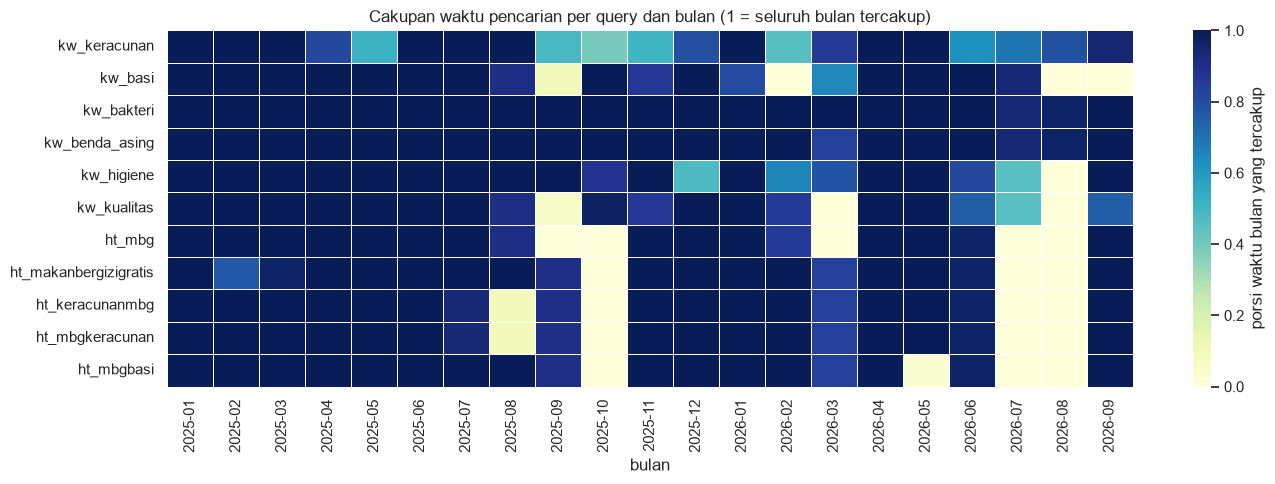

In [7]:
log_df = pd.DataFrame([json.loads(line) for line in EDA_LOG.open(encoding="utf-8")])
akhir = log_df.drop_duplicates("search_id", keep="last").copy()  # status terakhir tiap pencarian
bagian = akhir["search_id"].str.split("|", expand=True)
akhir["query_id"] = bagian[0]
akhir["ws"] = pd.to_datetime(bagian[1], utc=True)
akhir["we"] = pd.to_datetime(bagian[2], utc=True)
akhir["saturated"] = akhir["saturated"].fillna(False).astype(bool)

riwayat_error = set(log_df.loc[log_df["status"] == "error", "search_id"])
pulih = akhir[akhir["search_id"].isin(riwayat_error) & (akhir["status"] != "error")]
print(f"Baris log: {len(log_df)} | pencarian unik: {len(akhir)}")
print("Status akhir:", akhir["status"].value_counts().to_dict())
print(f"Pencarian yang pernah error tetapi akhirnya berhasil diulang: {len(pulih)} dari {len(riwayat_error)}")
print("Jendela jenuh (100 unggahan pada jendela terkecil):", int(akhir["saturated"].sum()))
print("Rata-rata unggahan per pencarian berstatus ok:", round(akhir.loc[akhir["status"] == "ok", "n_posts"].mean(), 1))

# Cakupan waktu per query: gabungan jendela berstatus ok/no_results ('split' dihitung lewat anak-anaknya)
tercakup = akhir[akhir["status"].isin(["ok", "no_results"])]
mulai, selesai = akhir["ws"].min(), akhir["we"].max()
batas_bulan = list(pd.date_range(mulai, selesai, freq="MS")) + [selesai]
label_bulan = [b.strftime("%Y-%m") for b in batas_bulan[:-1]]
jam_bulan = np.array([(b1 - b0) / pd.Timedelta(hours=1) for b0, b1 in zip(batas_bulan[:-1], batas_bulan[1:])])


def gabung_interval(interval):
    hasil = []
    for s, e in sorted(interval):
        if hasil and s <= hasil[-1][1]:
            hasil[-1][1] = max(hasil[-1][1], e)
        else:
            hasil.append([s, e])
    return hasil


cakupan = {}
for q in URUTAN_QUERY:
    g = tercakup[tercakup["query_id"] == q]
    iv = gabung_interval(zip(g["ws"], g["we"]))
    cakupan[q] = [
        sum((max(pd.Timedelta(0), min(e, b1) - max(s, b0)) for s, e in iv), pd.Timedelta(0)) / (b1 - b0)
        for b0, b1 in zip(batas_bulan[:-1], batas_bulan[1:])
    ]
cakupan = pd.DataFrame(cakupan, index=label_bulan).T

ringkasan = pd.DataFrame({
    "pencarian_unik": akhir.groupby("query_id").size(),
    "error_akhir": akhir[akhir["status"] == "error"].groupby("query_id").size(),
    "jenuh": akhir[akhir["saturated"]].groupby("query_id").size(),
}).reindex(URUTAN_QUERY).fillna(0).astype(int)
ringkasan["cakupan_waktu_persen"] = (cakupan.values * jam_bulan).sum(axis=1) / jam_bulan.sum() * 100
print(f"\nPeriode pencarian: {mulai.date()} -> {selesai.date()} (akhir eksklusif)")
print(ringkasan.round(1).to_string())

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(cakupan, vmin=0, vmax=1, cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "porsi waktu bulan yang tercakup"}, ax=ax)
ax.set_title("Cakupan waktu pencarian per query dan bulan (1 = seluruh bulan tercakup)")
ax.set_xlabel("bulan")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Dataset hanya memuat unggahan yang berhasil ditemukan, sehingga kelengkapannya perlu dibaca dari log pencarian. Dari **881 pencarian unik**, status akhirnya adalah `ok` 453, `split` 332 (dibelah menjadi jendela lebih sempit, dan hasilnya diambil dari jendela anak), `no_results` 42, dan **`error` 54**. Sebanyak 107 pencarian pernah error, dan 53 di antaranya berhasil diulang sampai sukses. Ada **8 jendela jenuh** (tepat 100 unggahan pada jendela terkecil 6 jam atau lebih), seluruhnya milik `kw_keracunan` pada 29 September–3 Oktober 2025, sehingga sebagian unggahan pada puncak isu tersebut hampir pasti tidak terambil.

Cakupan waktu per query (gabungan jendela berstatus `ok` atau `no_results`) tidak seragam:

* `kw_bakteri` (99,5%) dan `kw_benda_asing` (98,7%) hampir penuh.
* `kw_higiene` 85,8%, `ht_makanbergizigratis` 82,8%, `kw_keracunan` 80,3%, `kw_kualitas` 79,0%, dan `kw_basi` 77,9%.
* `ht_mbg` hanya 74,6%, sedangkan tiga hashtag lain sekitar 79,3%.

Peta panas memperlihatkan **celah yang mengelompok**: hashtag tidak tercakup terutama pada Oktober 2025 dan Juli–Agustus 2026, `kw_basi` kosong pada September 2025, Februari 2026, dan Agustus–September 2026, serta `kw_kualitas` pada September 2025, Maret 2026, dan Agustus 2026. Sel kosong pada peta ini berarti **pencarian belum berhasil dijalankan**, bukan berarti tidak ada unggahan. Angka ini juga menjadi dasar untuk membaca grafik tren di bagian 2.2.12–2.2.15.

### 2.2.6 Statistik Deskriptif Kolom Engagement

In [8]:
desc = df[COUNT_COLS].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
desc["skewness"] = df[COUNT_COLS].skew()
desc["persen_nol"] = (df[COUNT_COLS] == 0).mean() * 100
desc.round(1)

,count,mean,std,min,25%,50%,75%,90%,99%,max,skewness,persen_nol
reply_count,24535.0,13.6,70.1,0.0,0.0,1.0,4.0,21.0,252.7,3226.0,19.1,39.6
repost_count,24535.0,113.3,1028.9,0.0,0.0,1.0,7.0,54.0,2690.0,50025.0,22.6,42.6
like_count,24535.0,325.9,2693.9,0.0,2.0,6.0,28.0,185.0,7257.2,119734.0,20.4,8.5
quote_count,24535.0,8.1,112.3,0.0,0.0,0.0,1.0,4.0,147.0,11363.0,62.5,71.7
view_count,24535.0,15125.7,112052.8,4.0,247.0,806.0,3049.0,13473.0,302644.7,5344991.0,20.3,0.0


Semua metrik engagement **sangat condong ke kanan** (skewness 19,1–62,5): median jauh lebih kecil daripada rata-rata. Median `like_count` hanya 6 dengan rata-rata 325,9, dan median `view_count` 806 dengan rata-rata 15.126. Persentil ke-99 `like_count` sudah mencapai 7.257 dan maksimumnya 119.734, yang berarti sebagian kecil unggahan viral menarik rata-rata ke atas.

Banyak unggahan tidak mendapat interaksi sama sekali: **71,7%** tidak punya quote, **42,6%** tidak di-repost, dan **39,6%** tidak dibalas. Hanya 8,5% yang tanpa like, dan `view_count` tidak pernah nol (minimum 4). Untuk perbandingan engagement, median dan persentil lebih representatif daripada rata-rata.

### 2.2.7 Distribusi Engagement (Histogram)

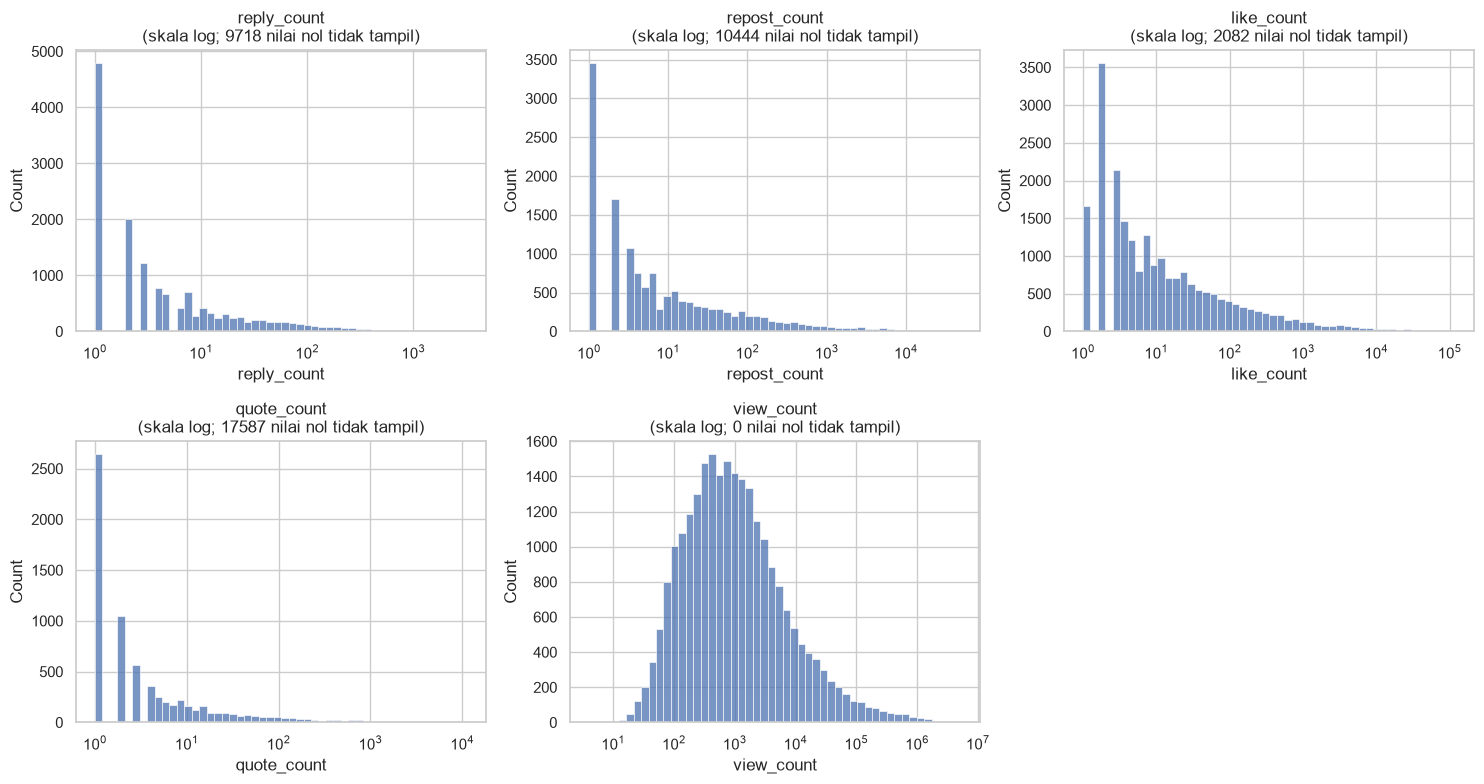

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, kolom in zip(axes.flat, COUNT_COLS):
    n_nol = int((df[kolom] == 0).sum())
    sns.histplot(df.loc[df[kolom] > 0, kolom], bins=50, log_scale=True, ax=ax)
    ax.set_title(f"{kolom}\n(skala log; {n_nol} nilai nol tidak tampil)")
    ax.set_xlabel(kolom)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

Pada skala logaritmik, `view_count` mendekati bentuk lonceng dengan pusat di kisaran ratusan sampai ribuan view dan ekor panjang sampai jutaan. Empat metrik lainnya menumpuk di nilai 1–10 dengan ekor kanan yang panjang (hingga ribuan reply dan puluhan ribu repost); histogram ini hanya menampilkan nilai positif, sehingga banyaknya nilai nol (lihat judul tiap panel) tidak ikut terlihat. Bentuk ini menunjukkan data engagement mengikuti pola *heavy-tailed*: mayoritas unggahan kecil, segelintir unggahan sangat besar.

### 2.2.8 Deteksi Outlier Engagement (Boxplot)

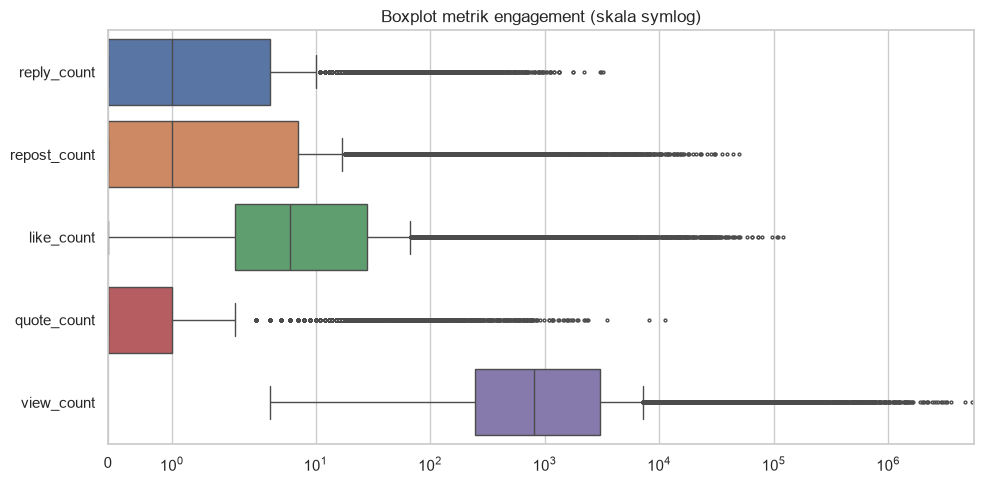

,Q1,Q3,batas_atas_IQR,jumlah_outlier,persen_outlier,maks
metrik,,,,,,
reply_count,0.0,4.0,10.0,3723,15.2,3226
repost_count,0.0,7.0,17.5,4036,16.4,50025
like_count,2.0,28.0,67.0,4077,16.6,119734
quote_count,0.0,1.0,2.5,3260,13.3,11363
view_count,247.0,3049.0,7252.0,3593,14.6,5344991


In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df[COUNT_COLS], orient="h", fliersize=2, ax=ax)
ax.set_xscale("symlog")
ax.set_xlim(left=0)
ax.set_title("Boxplot metrik engagement (skala symlog)")
plt.tight_layout()
plt.show()

baris = []
for kolom in COUNT_COLS:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    batas = q3 + 1.5 * (q3 - q1)
    n = int((df[kolom] > batas).sum())
    baris.append({"metrik": kolom, "Q1": q1, "Q3": q3, "batas_atas_IQR": batas, "jumlah_outlier": n,
                  "persen_outlier": round(n / len(df) * 100, 1), "maks": df[kolom].max()})
pd.DataFrame(baris).set_index("metrik")

Aturan IQR menandai **13,3–16,6%** unggahan sebagai outlier pada tiap metrik. Batas atasnya sangat rendah (`like_count` hanya 67 dan `view_count` 7.252), sehingga unggahan dengan engagement yang sebenarnya wajar pun tergolong outlier, dan nilai maksimum mencapai ratusan hingga ribuan kali lipat dari batas itu. Seperti pada referensi, outlier ini **mewakili unggahan viral yang nyata**, bukan kesalahan pengambilan data, sehingga tidak otomatis dihapus. Keputusan penanganannya (misalnya transformasi log atau analisis terpisah untuk unggahan viral) diambil pada tahap pre-processing.

### 2.2.9 Jenis Unggahan: Tweet Asli, Reply, dan Quote

               jumlah  persen
jenis                        
tweet asli      13985    57.0
reply            7779    31.7
quote            2481    10.1
reply + quote     290     1.2

Median engagement per jenis:
               reply_count  repost_count  like_count  quote_count  view_count
jenis                                                                        
quote                  1.0           3.0         9.0          0.0       707.0
reply                  0.0           0.0         5.0          0.0       664.0
reply + quote          1.0           2.0         7.0          0.0       845.5
tweet asli             2.0           2.0         5.0          0.0       923.0

Rata-rata engagement per jenis:
               reply_count  repost_count  like_count  quote_count  view_count
jenis                                                                        
quote                 11.7         249.0       635.9          8.4     24209.5
reply                  1.6           7.3        79.8   

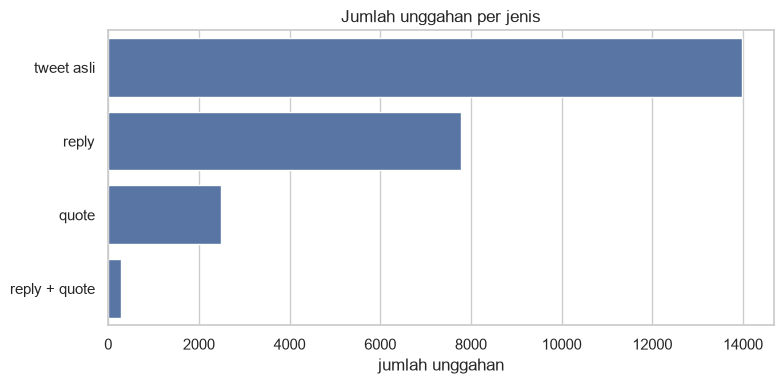

In [11]:
df["jenis"] = np.select(
    [df["is_reply"] & df["is_quote"], df["is_reply"], df["is_quote"]],
    ["reply + quote", "reply", "quote"],
    default="tweet asli",
)
jenis = df["jenis"].value_counts()
print(pd.DataFrame({"jumlah": jenis, "persen": (jenis / len(df) * 100).round(1)}).to_string())
print("\nMedian engagement per jenis:")
print(df.groupby("jenis")[COUNT_COLS].median().to_string())
print("\nRata-rata engagement per jenis:")
print(df.groupby("jenis")[COUNT_COLS].mean().round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=jenis.values, y=jenis.index, ax=ax)
ax.set_title("Jumlah unggahan per jenis")
ax.set_xlabel("jumlah unggahan")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Tweet asli menyusun **57,0%** data (13.985), diikuti reply **31,7%** (7.779), quote **10,1%** (2.481), dan 290 unggahan (1,2%) yang sekaligus reply dan quote. Hampir sepertiga data adalah balasan, sehingga banyak teks yang hanya bermakna jika dibaca bersama unggahan induknya (`parent_post_id` terisi pada 7.895 reply).

Perbedaan engagement antar jenis terlihat pada rata-rata: quote memiliki rata-rata like tertinggi (635,9) dan tweet asli rata-rata like 408,6, sedangkan reply hanya 79,8. Median ketiganya jauh lebih dekat (5–9 like), sehingga perbedaan rata-rata terutama didorong oleh segelintir unggahan viral.

### 2.2.10 Akun dengan Jumlah Unggahan Terbanyak

Akun unik: 7968
Akun yang hanya muncul sekali: 70.9%
Akun dengan >= 10 unggahan: 353 akun, menyumbang 50.9% unggahan
Kontribusi 10 akun teratas: 13.9%
Kontribusi 1% akun teratas (79 akun): 31.7%


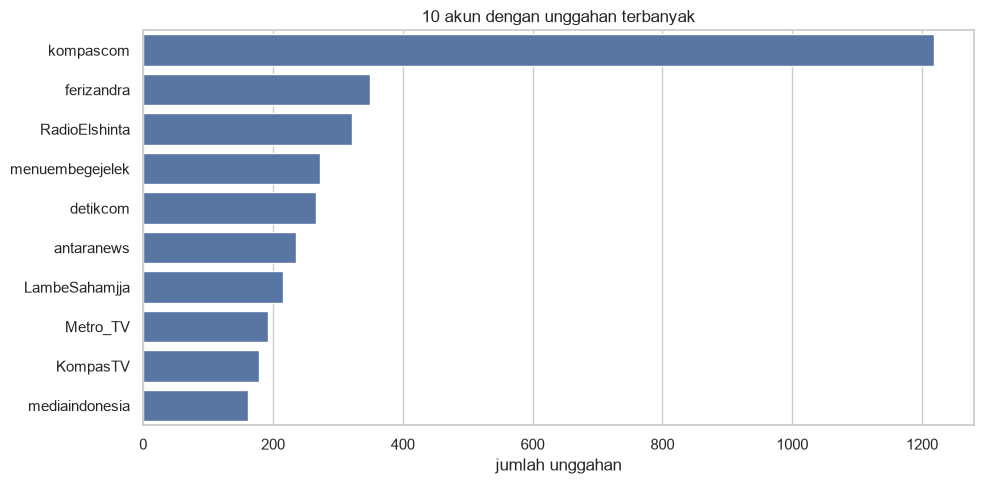

In [12]:
df["akun"] = tampil_handle(df["author_handle"])
per_akun = df["akun"].value_counts()
n_top1 = max(1, int(len(per_akun) * 0.01))
print("Akun unik:", len(per_akun))
print(f"Akun yang hanya muncul sekali: {(per_akun == 1).mean():.1%}")
print(f"Akun dengan >= 10 unggahan: {int((per_akun >= 10).sum())} akun, menyumbang {per_akun[per_akun >= 10].sum() / len(df):.1%} unggahan")
print(f"Kontribusi 10 akun teratas: {per_akun.head(10).sum() / len(df):.1%}")
print(f"Kontribusi 1% akun teratas ({n_top1} akun): {per_akun.head(n_top1).sum() / len(df):.1%}")

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=per_akun.head(10).values, y=per_akun.head(10).index, ax=ax)
ax.set_title("10 akun dengan unggahan terbanyak")
ax.set_xlabel("jumlah unggahan")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Dataset berasal dari **7.968 akun unik**. Distribusinya sangat timpang: **70,9% akun hanya muncul sekali**, sedangkan 353 akun dengan 10 unggahan atau lebih menyumbang **50,9%** seluruh unggahan. Satu persen akun teratas (79 akun) menyumbang 31,7% unggahan.

Sepuluh akun teratas menyumbang 13,9% unggahan, dan tujuh di antaranya adalah media berita: `kompascom` (1.219 unggahan, sekitar 5% dari seluruh dataset), `RadioElshinta`, `detikcom`, `antaranews`, `Metro_TV`, `KompasTV`, dan `mediaindonesia`. Tiga akun lainnya adalah akun non-media (`ferizandra`, `menuembegejelek`, `LambeSahamjja`). Dengan demikian, suara media dan segelintir akun aktif cukup dominan, dan data tidak sepenuhnya mewakili opini individu.

### 2.2.11 Akun dengan Total Like Tertinggi

In [13]:
akun_agg = df.groupby("akun").agg(
    jumlah_unggahan=("post_id", "size"),
    total_like=("like_count", "sum"),
    median_like=("like_count", "median"),
    total_view=("view_count", "sum"),
)
top_like = akun_agg.sort_values("total_like", ascending=False).head(10)
top_like["persen_total_like"] = (top_like["total_like"] / df["like_count"].sum() * 100).round(1)
print(f"10 akun teratas menyumbang {top_like['persen_total_like'].sum():.1f}% dari seluruh like")
top_like

10 akun teratas menyumbang 25.8% dari seluruh like


,jumlah_unggahan,total_like,median_like,total_view,persen_total_like
akun,,,,,
menuembegejelek,273,530689,354.0,32975477,6.6
whiterosestea,17,237891,3801.0,3995602,3.0
LambeSahamjja,215,222467,191.0,13652329,2.8
intinyadeh,20,195761,4892.0,8026226,2.4
kompascom,1219,182747,6.0,34431844,2.3
ardisatriawan,43,153583,1672.0,7823189,1.9
GusDikaOfficial,24,147688,1227.0,2282488,1.8
Hidupsebagai62,17,143339,49.0,2540932,1.8
dosenkesmas,93,134922,118.0,8172793,1.7


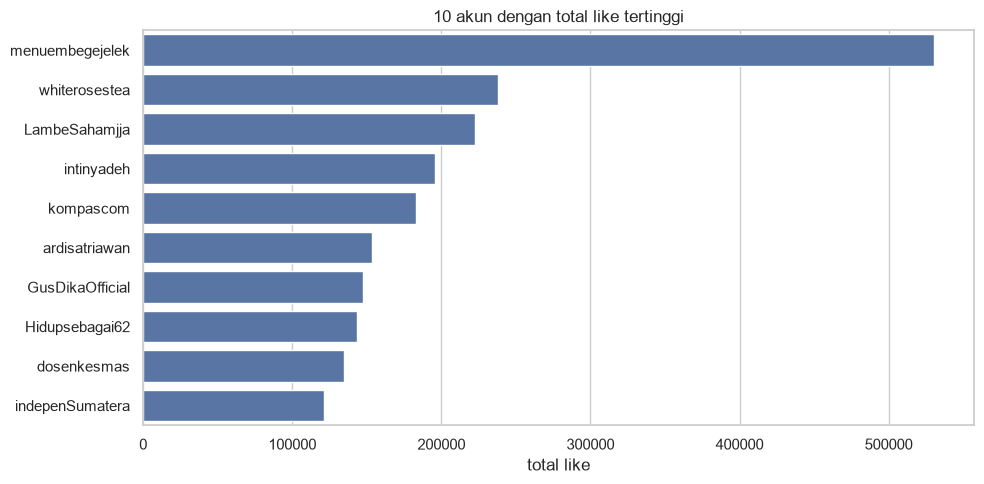

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_like["total_like"], y=top_like.index, ax=ax)
ax.set_title("10 akun dengan total like tertinggi")
ax.set_xlabel("total like")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Total like terbesar dimiliki `menuembegejelek` (530.689 like dari 273 unggahan, sekitar 6,6% dari seluruh like), disusul `whiterosestea`, `LambeSahamjja`, dan `intinyadeh`. Sepuluh akun teratas menyumbang **25,8%** total like.

Akun dengan unggahan terbanyak tidak selalu paling berpengaruh. `kompascom` punya 1.219 unggahan, tetapi median like per unggahan hanya 6. Sebaliknya, `whiterosestea` dan `intinyadeh` hanya memiliki 17 dan 20 unggahan, tetapi median like-nya 3.801 dan 4.892. Pola ini sejalan dengan perbedaan antara media yang mengandalkan volume dan akun individu yang mengandalkan unggahan viral.

### 2.2.12 Tren Jumlah Unggahan per Hari

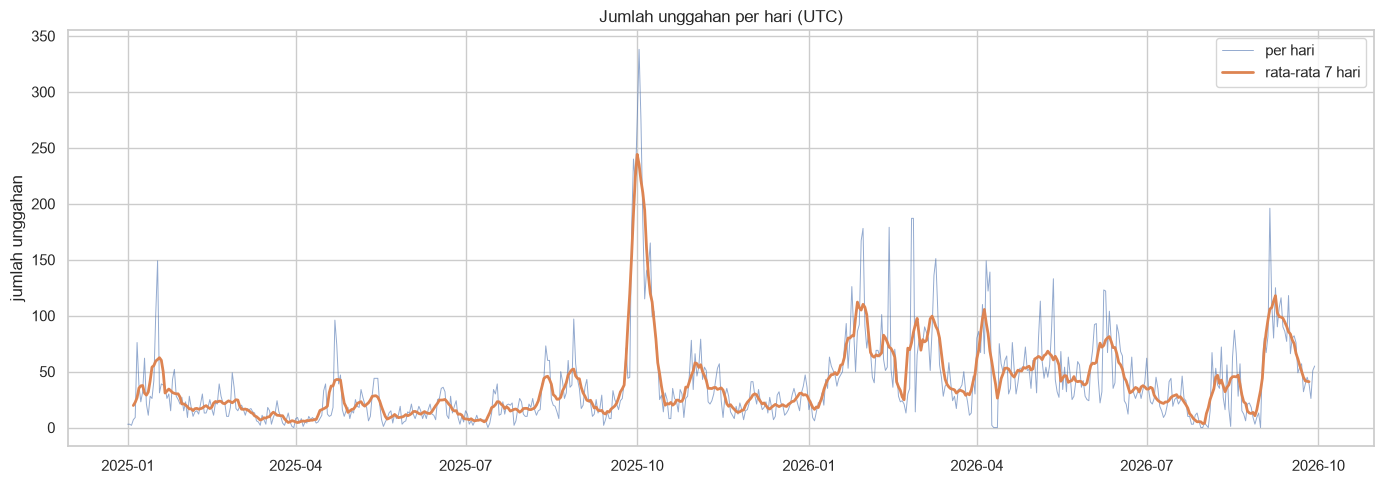

Rentang 637 hari | hari tanpa unggahan: 9
Median 26 | rata-rata 38.5 | maksimum 338 unggahan per hari

8 hari terpadat:
tanggal
2025-10-02    338
2025-10-01    275
2025-10-03    275
2025-09-29    240
2025-09-30    219
2026-09-05    196
2026-02-25    187
2026-02-26    187


In [15]:
df["tanggal"] = df["created_at"].dt.tz_convert(None).dt.normalize()  # tanggal UTC
harian = df.groupby("tanggal").size().asfreq("D", fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(harian.index, harian.values, lw=0.7, alpha=0.6, label="per hari")
ax.plot(harian.index, harian.rolling(7, center=True).mean(), lw=2, label="rata-rata 7 hari")
ax.set_title("Jumlah unggahan per hari (UTC)")
ax.set_ylabel("jumlah unggahan")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Rentang {len(harian)} hari | hari tanpa unggahan: {int((harian == 0).sum())}")
print(f"Median {harian.median():.0f} | rata-rata {harian.mean():.1f} | maksimum {harian.max()} unggahan per hari")
print("\n8 hari terpadat:")
print(harian.sort_values(ascending=False).head(8).to_string())

Volume harian umumnya berkisar belasan sampai puluhan unggahan pada 2025 (median seluruh periode 26 per hari, rata-rata 38,5), lalu naik menjadi sekitar 30–100 unggahan per hari pada 2026. Hanya 9 dari 637 hari yang tidak memiliki unggahan.

Lonjakan paling jelas terjadi pada **29 September–3 Oktober 2025** (219–338 unggahan per hari, puncak 338 pada 2 Oktober 2025). Lonjakan lain yang lebih kecil terlihat pada 25–26 Februari 2026 (187 per hari) dan 5 September 2026 (196). Sebaliknya, ada lembah panjang pada Juli–Agustus 2026. Karena sebagian lonjakan (terutama akhir September–awal Oktober 2025) berada pada periode dengan jendela jenuh dan cakupan rendah (bagian 2.2.5), **puncak sebenarnya kemungkinan lebih tinggi daripada yang terlihat**.

### 2.2.13 Tren Jumlah Unggahan per Bulan

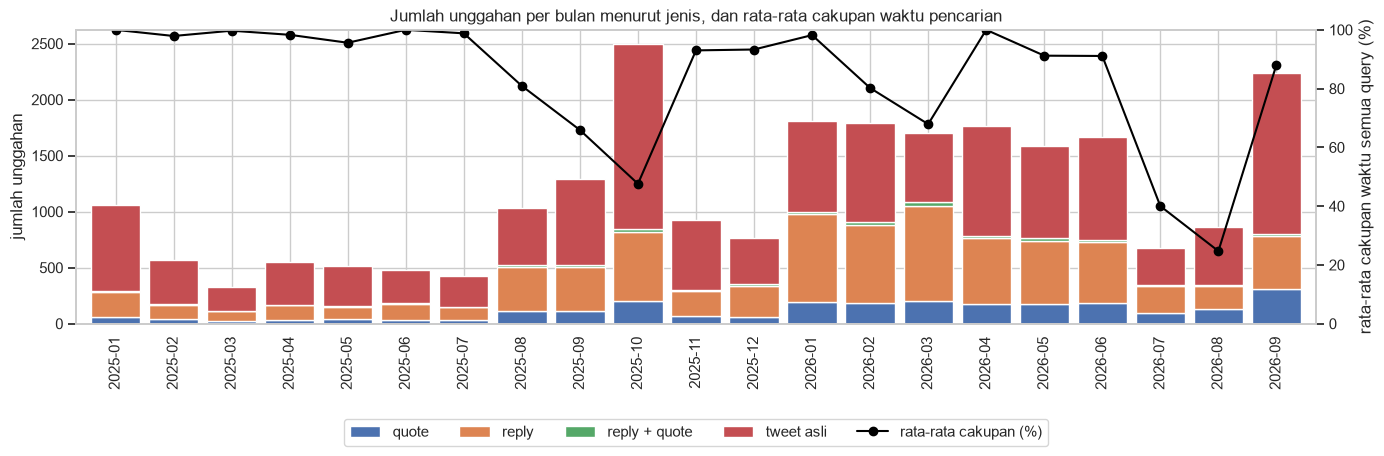

Korelasi Spearman jumlah unggahan bulanan vs rata-rata cakupan: -0.4


jenis,quote,reply,reply + quote,tweet asli,total,cakupan_rata2_persen
bulan,,,,,,
2025-01,56,230,5,769,1060,100.0
2025-02,44,123,10,394,571,97.9
2025-03,27,83,3,217,330,99.7
2025-04,36,127,1,382,546,98.3
2025-05,43,109,6,361,519,95.6
2025-06,32,146,5,298,481,100.0
2025-07,31,115,4,272,422,98.8
2025-08,115,391,14,511,1031,80.9
2025-09,113,396,12,767,1288,65.9


In [16]:
df["bulan"] = df["tanggal"].dt.strftime("%Y-%m")
bulanan = df.groupby(["bulan", "jenis"]).size().unstack(fill_value=0)
bulanan["total"] = bulanan.sum(axis=1)
bulanan["cakupan_rata2_persen"] = (cakupan.mean() * 100).reindex(bulanan.index).round(1)  # dari sel 2.2.5

fig, ax = plt.subplots(figsize=(14, 5))
bulanan.drop(columns=["total", "cakupan_rata2_persen"]).plot(kind="bar", stacked=True, width=0.85, ax=ax)
ax.set_title("Jumlah unggahan per bulan menurut jenis, dan rata-rata cakupan waktu pencarian")
ax.set_xlabel("")
ax.set_ylabel("jumlah unggahan")
ax2 = ax.twinx()
ax2.plot(range(len(bulanan)), bulanan["cakupan_rata2_persen"], color="black", marker="o", lw=1.5, label="rata-rata cakupan (%)")
ax2.set_ylim(0, 100)
ax2.set_ylabel("rata-rata cakupan waktu semua query (%)")
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=5)
plt.tight_layout()
plt.show()

print("Korelasi Spearman jumlah unggahan bulanan vs rata-rata cakupan:", round(bulanan["total"].rank().corr(bulanan["cakupan_rata2_persen"].rank()), 2))
bulanan

Volume bulanan relatif rendah pada paruh pertama 2025 (330–1.060 unggahan per bulan, terendah pada Maret 2025), mulai naik pada Agustus–September 2025, dan mencapai puncak **2.498 unggahan pada Oktober 2025**. Setelah itu volume turun ke 764–929 pada November–Desember 2025, naik lagi ke sekitar 1.600–1.800 per bulan pada Januari–Juni 2026, turun ke 674 dan 867 pada Juli–Agustus 2026, lalu melonjak ke 2.235 pada September 2026.

Garis hitam menunjukkan rata-rata cakupan waktu pencarian semua query. Ketidakmerataan volume **tidak sepenuhnya mencerminkan perilaku pengguna**: cakupan Oktober 2025 hanya 47,6%, Juli 2026 40,0%, dan Agustus 2026 24,7%. Lembah Juli–Agustus 2026 kemungkinan sebagian besar akibat pencarian yang belum berhasil, bukan penurunan percakapan. Korelasi peringkat antara volume dan cakupan bernilai negatif (-0,40) karena periode lonjakan isu justru paling sering memicu jendela jenuh dan error. **Perbandingan volume antar bulan sebaiknya tidak dibaca sebagai tren yang murni.**

### 2.2.14 Pola Waktu Unggah (Hari dan Jam)

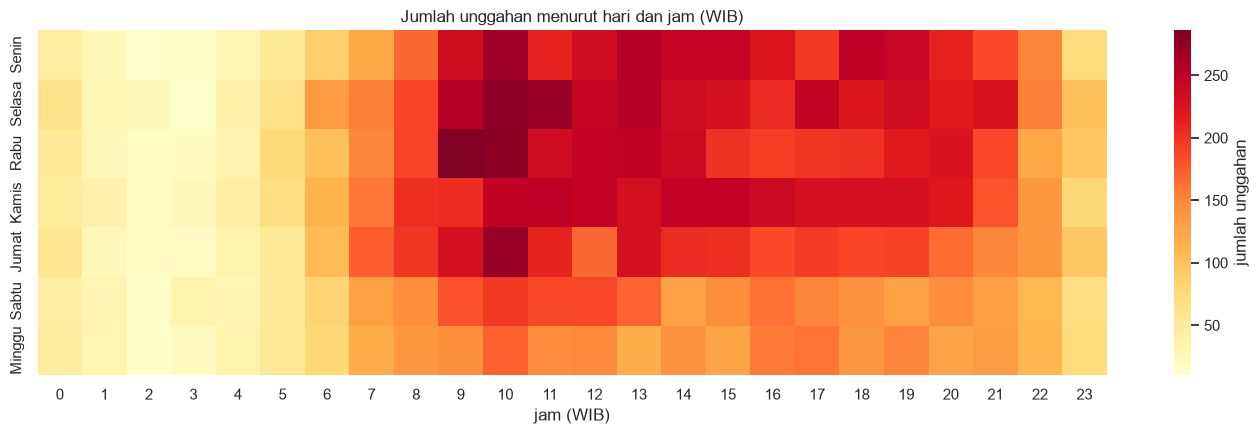

Unggahan pukul 06.00-21.59 WIB: 87.9%
Jam puncak: 10.00 WIB (1710 unggahan) | jam sepi: 2.00 WIB (116 unggahan)
Per hari: {'Senin': 3780, 'Selasa': 4083, 'Rabu': 3842, 'Kamis': 3931, 'Jumat': 3505, 'Sabtu': 2805, 'Minggu': 2589}
Akhir pekan (Sabtu-Minggu): 22.0%


In [17]:
wib = df["created_at"].dt.tz_convert("Asia/Jakarta")
pola = pd.crosstab(wib.dt.dayofweek, wib.dt.hour).reindex(index=range(7), columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(pola, cmap="YlOrRd", yticklabels=HARI, ax=ax, cbar_kws={"label": "jumlah unggahan"})
ax.set_title("Jumlah unggahan menurut hari dan jam (WIB)")
ax.set_xlabel("jam (WIB)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

per_jam = wib.dt.hour.value_counts().sort_index()
per_hari = wib.dt.dayofweek.value_counts().sort_index()
print(f"Unggahan pukul 06.00-21.59 WIB: {per_jam.loc[6:21].sum() / len(df):.1%}")
print(f"Jam puncak: {per_jam.idxmax()}.00 WIB ({per_jam.max()} unggahan) | jam sepi: {per_jam.idxmin()}.00 WIB ({per_jam.min()} unggahan)")
print("Per hari:", {HARI[i]: int(n) for i, n in per_hari.items()})
print(f"Akhir pekan (Sabtu-Minggu): {per_hari.loc[5:6].sum() / len(df):.1%}")

Aktivitas mengikuti ritme harian: **87,9%** unggahan terjadi pukul 06.00–21.59 WIB, dengan puncak pukul 10.00 WIB (1.710 unggahan) dan titik terendah pukul 02.00 WIB (116 unggahan). Hari kerja lebih ramai daripada akhir pekan: Selasa paling tinggi (4.083 unggahan), sedangkan Sabtu dan Minggu hanya menyumbang **22,0%** dari seluruh unggahan. Pola ini konsisten dengan dominasi akun media berita dalam dataset. Seluruh pola jam memakai WIB karena penutur dan peristiwa yang dibahas berada di Indonesia.

### 2.2.15 Kontribusi Query Pencarian

                       ditemukan_pertama_oleh  dicocokkan_oleh_query  persen_dari_unggahan
kw_keracunan                             8521                   8767                  35.7
kw_basi                                  1716                   1900                   7.7
kw_bakteri                                624                    730                   3.0
kw_benda_asing                           1416                   1628                   6.6
kw_higiene                               6124                   6897                  28.1
kw_kualitas                              2670                   3187                  13.0
ht_mbg                                   1802                   2028                   8.3
ht_makanbergizigratis                    1574                   1984                   8.1
ht_keracunanmbg                            87                    123                   0.5
ht_mbgkeracunan                             0                      0                   0.0

Hanya kata kunci: 20746 | hanya hashtag: 3391 | keduanya: 398
Dua query teratas mencakup 63.8% unggahan (satu unggahan bisa dihitung di beberapa query)


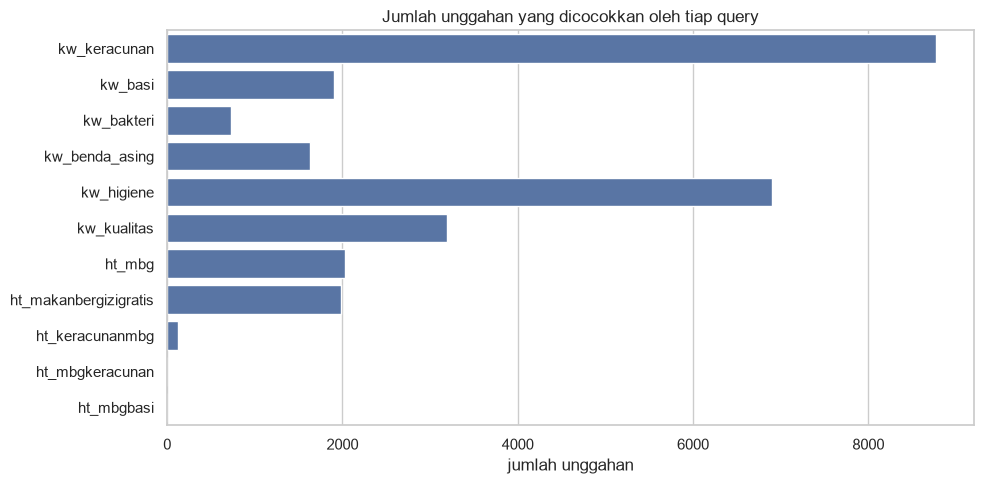

In [18]:
pertama = df["query_id"].value_counts()
cocok = df["matched_query_ids"].str.split("|").explode().value_counts()
tabel_query = pd.DataFrame({"ditemukan_pertama_oleh": pertama, "dicocokkan_oleh_query": cocok}).reindex(URUTAN_QUERY).fillna(0).astype(int)
tabel_query["persen_dari_unggahan"] = (tabel_query["dicocokkan_oleh_query"] / len(df) * 100).round(1)
print(tabel_query.to_string())

n_query = df["matched_query_ids"].str.count(r"\|") + 1
print("\nJumlah query berbeda yang menemukan satu unggahan:", n_query.value_counts().sort_index().to_dict())
print(f"Unggahan yang ditemukan >1 query: {(n_query > 1).mean():.1%}")
kw = df["matched_query_ids"].str.contains("kw_")
ht = df["matched_query_ids"].str.contains("ht_")
print(f"Hanya kata kunci: {(kw & ~ht).sum()} | hanya hashtag: {(ht & ~kw).sum()} | keduanya: {(kw & ht).sum()}")
top2 = tabel_query["persen_dari_unggahan"].sort_values(ascending=False).head(2).sum()
print(f"Dua query teratas mencakup {top2:.1f}% unggahan (satu unggahan bisa dihitung di beberapa query)")

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=tabel_query["dicocokkan_oleh_query"], y=tabel_query.index, ax=ax)
ax.set_title("Jumlah unggahan yang dicocokkan oleh tiap query")
ax.set_xlabel("jumlah unggahan")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

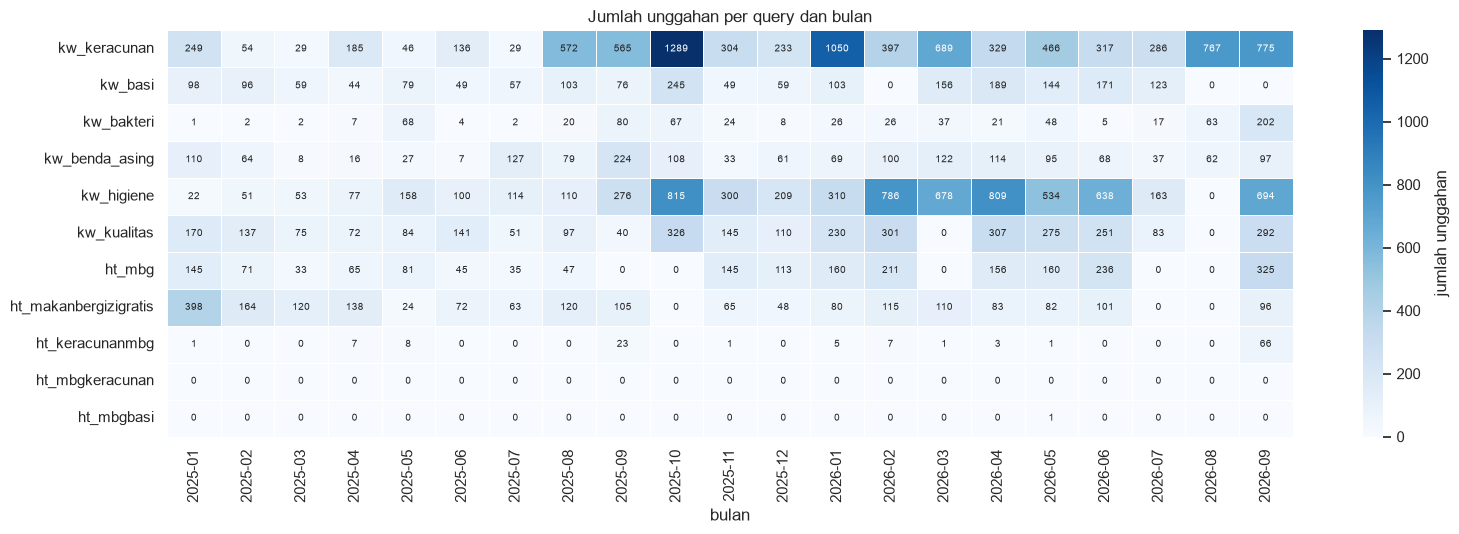

In [19]:
# Sebaran unggahan per query dan bulan (satu unggahan dihitung pada setiap query yang menemukannya)
per_query_bulan = (
    df[["bulan", "matched_query_ids"]]
    .assign(q=df["matched_query_ids"].str.split("|"))
    .explode("q")
    .groupby(["q", "bulan"])
    .size()
    .unstack(fill_value=0)
    .reindex(URUTAN_QUERY)
    .fillna(0)
    .astype(int)
)

fig, ax = plt.subplots(figsize=(16, 5.5))
sns.heatmap(per_query_bulan, annot=True, fmt="d", annot_kws={"size": 7}, cmap="Blues", linewidths=0.4, ax=ax,
            cbar_kws={"label": "jumlah unggahan"})
ax.set_title("Jumlah unggahan per query dan bulan")
ax.set_xlabel("bulan")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

`kw_keracunan` mencocokkan paling banyak unggahan (8.767; **35,7%**), disusul `kw_higiene` (6.897; 28,1%) dan `kw_kualitas` (3.187; 13,0%). Dua query teratas saja mencakup sekitar 63,8% unggahan (satu unggahan bisa dihitung di lebih dari satu query). Hashtag yang paling produktif adalah `#MBG` (2.028) dan `#MakanBergiziGratis` (1.984), sedangkan `#KeracunanMBG` hanya 123, `#MBGBasi` hanya 1, dan `#MBGKeracunan` tidak menemukan unggahan sama sekali. Jadi hashtag isu keamanan pangan jarang dipakai dibandingkan hashtag umum program.

Sebanyak **10,0%** unggahan ditemukan oleh lebih dari satu query (2.215 oleh dua query, 225 oleh tiga, dan 15 oleh empat), dan 398 unggahan ditemukan oleh kata kunci sekaligus hashtag. Dominasi query ini **bukan masalah dengan sendirinya** karena `post_id` sudah unik, tetapi ada dua hal yang perlu diwaspadai:

* Query berbeda luasnya: `kw_higiene` memuat istilah umum `SPPG`, dan `kw_keracunan` mencakup konteks politik atau komentar umum, sehingga hasil query **tidak sama dengan label topik**.
* Peta panas query per bulan memperlihatkan **komposisi berubah antar waktu**. `kw_higiene` hanya 22–77 unggahan per bulan pada Januari–April 2025, tetapi sekitar 530–810 per bulan pada Februari–Juni dan September 2026, kemungkinan karena istilah SPPG baru banyak dipakai setelah dapur-dapur MBG beroperasi. Selain itu sel bernilai nol (misalnya `kw_basi` pada Februari dan Agustus–September 2026) sebagian besar disebabkan celah pengumpulan di bagian 2.2.5.

### 2.2.16 Karakteristik Teks (Panjang, URL, Hashtag, Mention)

Panjang teks (karakter):
count    24535.0
mean       377.0
std        578.0
min          7.0
25%        166.0
50%        249.0
75%        312.0
95%       1230.0
99%       3313.0
max      10410.0

Teks sangat pendek (< 30 karakter): 189 (0.8%)
Teks panjang (> 280 karakter)      : 6889 (28.1%)
Mengandung URL     : 21.5%
Mengandung hashtag : 27.0% (rata-rata 3.3 per unggahan ber-hashtag)
Mengandung mention : 7.5%

Median panjang teks per jenis:
jenis
quote            231.0
reply            209.0
reply + quote    250.5
tweet asli       270.0


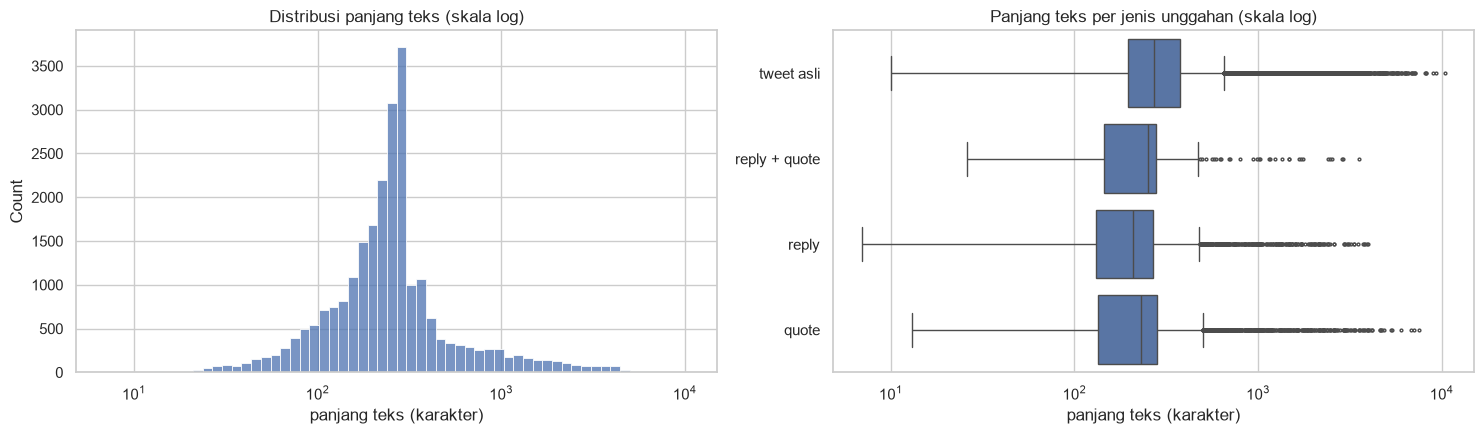

In [20]:
df["panjang_teks"] = df["text"].str.len()
df["n_url"] = df["text"].str.count(r"https?://\S+")
df["n_hashtag"] = df["text"].str.count(r"#\w+")
df["n_mention"] = df["text"].str.count(r"@\w+")

print("Panjang teks (karakter):")
print(df["panjang_teks"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(0).to_string())
print(f"\nTeks sangat pendek (< 30 karakter): {(df['panjang_teks'] < 30).sum()} ({(df['panjang_teks'] < 30).mean():.1%})")
print(f"Teks panjang (> 280 karakter)      : {(df['panjang_teks'] > 280).sum()} ({(df['panjang_teks'] > 280).mean():.1%})")
print(f"Mengandung URL     : {(df['n_url'] > 0).mean():.1%}")
print(f"Mengandung hashtag : {(df['n_hashtag'] > 0).mean():.1%} (rata-rata {df.loc[df['n_hashtag'] > 0, 'n_hashtag'].mean():.1f} per unggahan ber-hashtag)")
print(f"Mengandung mention : {(df['n_mention'] > 0).mean():.1%}")
print("\nMedian panjang teks per jenis:")
print(df.groupby("jenis")["panjang_teks"].median().to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(df["panjang_teks"], bins=60, log_scale=True, ax=axes[0])
axes[0].set_title("Distribusi panjang teks (skala log)")
axes[0].set_xlabel("panjang teks (karakter)")
sns.boxplot(data=df, x="panjang_teks", y="jenis", fliersize=2, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Panjang teks per jenis unggahan (skala log)")
axes[1].set_xlabel("panjang teks (karakter)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

Teks bermedian **249 karakter** (rata-rata 377), tetapi ekor panjang: persentil ke-95 sebesar 1.230 karakter dan maksimum 10.410. Distribusinya memuncak sekitar 250–280 karakter (batas klasik panjang tweet), sedangkan **28,1%** unggahan melebihi 280 karakter, kemungkinan unggahan panjang atau salinan artikel. Hanya 189 teks (0,8%) yang sangat pendek (kurang dari 30 karakter).

Sebanyak 21,5% unggahan memuat URL, 27,0% memuat hashtag (rata-rata 3,3 hashtag per unggahan ber-hashtag), dan 7,5% memuat mention. Tweet asli paling panjang (median 270 karakter), sedangkan reply paling pendek (209 karakter), sejalan dengan sifat balasan yang lebih singkat. Teks mentah masih bercampur URL, hashtag, mention, dan emoji, sehingga perlu dibersihkan pada tahap pre-processing.

### 2.2.17 Teks Duplikat dan Konten Berulang

In [21]:
frekuensi_teks = df["text"].value_counts()
berulang = frekuensi_teks[frekuensi_teks > 1]
print(f"Grup teks identik (persis sama): {len(berulang)} grup, mencakup {int(berulang.sum())} unggahan ({berulang.sum() / len(df):.1%})")

ringkas_ulang = (
    df[df["text"].isin(berulang.index)]
    .groupby("text")
    .agg(jumlah=("post_id", "size"), akun_unik=("author_handle", "nunique"), median_like=("like_count", "median"))
    .sort_values("jumlah", ascending=False)
)
print(f"Grup yang diposting oleh >= 2 akun berbeda: {int((ringkas_ulang['akun_unik'] > 1).sum())}")
print(f"Grup yang diposting satu akun saja        : {int((ringkas_ulang['akun_unik'] == 1).sum())}")

top_ulang = ringkas_ulang.head(10).copy()
top_ulang.insert(0, "teks", potong(top_ulang.index.to_series()))
top_ulang.reset_index(drop=True)

Grup teks identik (persis sama): 376 grup, mencakup 890 unggahan (3.6%)
Grup yang diposting oleh >= 2 akun berbeda: 123
Grup yang diposting satu akun saja        : 253


,teks,jumlah,akun_unik,median_like
0,"Kandungan Gizi Belalang dan Ulat Sagu, Serangga yang Berpotensi Jadi Menu MBG https://www.inews.id/lifestyle/h",11,1,1.0
1,Kata Istana soal Puluhan Siswa SD di Sukoharjo Diduga Keracunan usai Santap MBG https://www.inews.id/news/nasi,9,1,0.0
2,Perbaikan Program Makan Bergizi Gratis adalah langkah nyata memastikan anak-anak Indonesia memperoleh gizi ter,8,8,6.0
3,Evaluasi Program Makan Bergizi Gratis menjadi bukti keseriusan Presiden Prabowo dalam memastikan program berja,7,5,10.0
4,"RP5 TRILIUN DIGELONTORKAN UNTUK PAPUA! ""Semoga dananya tidak dikorupsi oleh para pejabat-pejabat yang berwatak",6,1,2.5
5,Penataan MBG melalui evaluasi dan penajaman sasaran menunjukkan komitmen pemerintah untuk memastikan program l,6,2,3.0
6,"Makan Bergizi Gratis bukan sekadar program, tapi investasi masa depan dari piring anak-anak hari ini, lahir SD",6,2,3.0
7,Program Makan Bergizi Gratis (MBG) terus didorong agar tepat sasaran dan dapat dirasakan oleh anak-anak yang b,5,5,7.0
8,"Puluhan Pelajar MAN I Cianjur Keracunan, Diduga usai Santap Makan Bergizi Gratis https://jabar.inews.id/berita",5,1,0.0
9,Dukung Bersama Program Makan Bergizi Gratis #ManfaatMakanBergiziGratis #MakanBergiziGratis,5,1,1.0


Terdapat **376 grup teks yang persis sama** dan mencakup **890 unggahan (3,6%)**. Sebanyak 253 grup diposting oleh satu akun saja (misalnya akun berita yang mengulang tautan artikel yang sama), sedangkan **123 grup diposting oleh dua akun atau lebih** dengan isi yang sama persis. Contoh paling jelas adalah kalimat pendukung program (misalnya "Perbaikan Program Makan Bergizi Gratis adalah langkah nyata..." oleh 8 akun berbeda), yang mengindikasikan unggahan terkoordinasi atau salin-tempel kampanye.

Pengecekan ini hanya menghitung teks yang identik karakter demi karakter, sehingga kemiripan yang hanya berbeda sedikit (tautan atau hashtag berbeda) tidak terdeteksi. Konten berulang dapat menggembungkan frekuensi topik atau sentimen tertentu, sehingga keputusan menghapus atau memberi bobot pada duplikat dibahas pada tahap pre-processing.

### 2.2.18 Hashtag Paling Sering Muncul

Unggahan ber-hashtag: 27.0% | total kemunculan: 21761 | hashtag unik: 4175


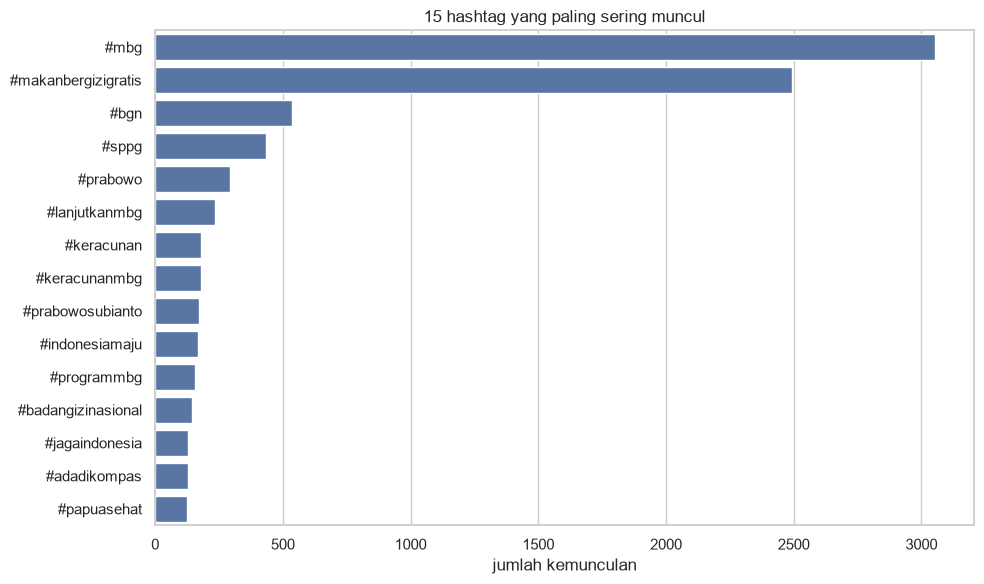

In [22]:
# Hashtag tidak membedakan huruf besar/kecil di X, sehingga penghitungan ini menyamakannya hanya untuk rekap (dataset tidak diubah)
semua_hashtag = df["text"].str.findall(r"#\w+").explode().dropna().str.lower()
hitung_hashtag = semua_hashtag.value_counts()
print(f"Unggahan ber-hashtag: {(df['n_hashtag'] > 0).mean():.1%} | total kemunculan: {len(semua_hashtag)} | hashtag unik: {len(hitung_hashtag)}")

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=hitung_hashtag.head(15).values, y=hitung_hashtag.head(15).index, ax=ax)
ax.set_title("15 hashtag yang paling sering muncul")
ax.set_xlabel("jumlah kemunculan")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Sebanyak 27,0% unggahan memakai hashtag, dengan total 21.761 kemunculan dan 4.175 hashtag unik. Hashtag teratas adalah `#mbg` (3.053) dan `#makanbergizigratis` (2.495), yang wajar karena keduanya juga menjadi query pencarian. Hashtag berikutnya, yaitu `#bgn`, `#sppg`, `#prabowo`, dan `#lanjutkanmbg`, memperlihatkan kuatnya **hashtag program dan kampanye**. Hashtag terkait keracunan (`#keracunan` dan `#keracunanmbg`, masing-masing 181) jauh lebih jarang. Dengan demikian, percakapan ber-hashtag dalam dataset lebih banyak bernada promosi atau dukungan program daripada keluhan keamanan pangan.

### 2.2.19 Korelasi Antar Metrik Engagement

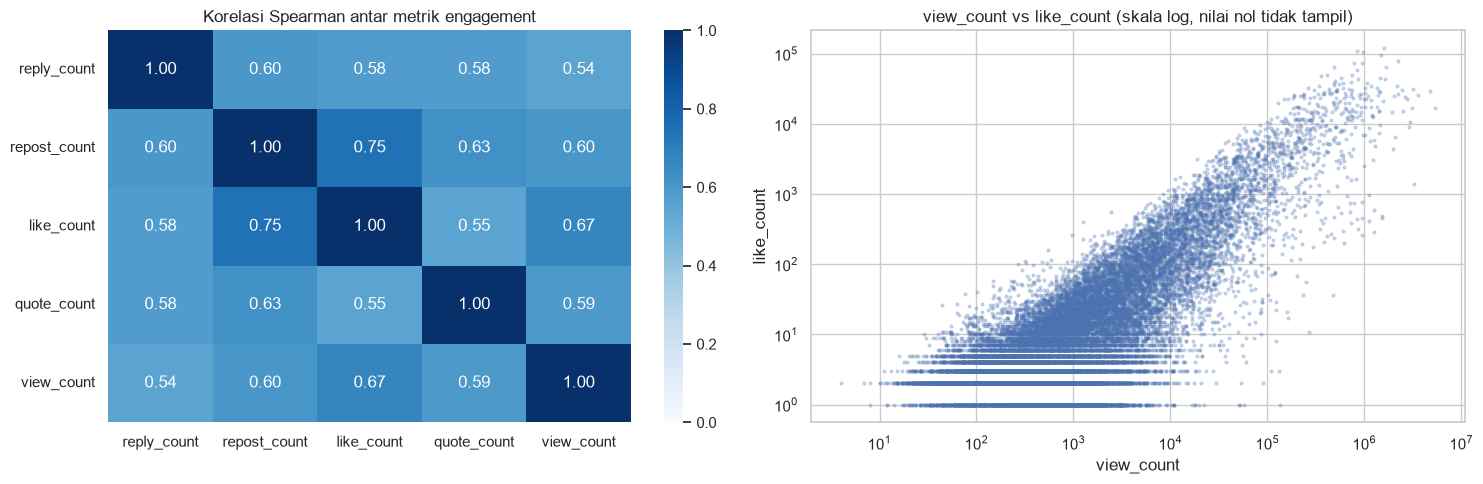

In [23]:
korelasi = df[COUNT_COLS].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Korelasi Spearman antar metrik engagement")

positif = df[(df["like_count"] > 0) & (df["view_count"] > 0)]
axes[1].scatter(positif["view_count"], positif["like_count"], s=4, alpha=0.25)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("view_count vs like_count (skala log, nilai nol tidak tampil)")
axes[1].set_xlabel("view_count")
axes[1].set_ylabel("like_count")
plt.tight_layout()
plt.show()

Korelasi Spearman antar metrik berada pada rentang **0,54–0,75**, terkuat antara `repost_count` dan `like_count` (0,75), lalu `like_count` dan `view_count` (0,67). Hubungan terlemah adalah `like_count` dengan `quote_count` (0,55). Seluruh korelasi positif dan sedang, artinya engagement cenderung naik bersamaan, tetapi tiap metrik menangkap aspek berbeda: view mencerminkan jangkauan, sedangkan like, repost, reply, dan quote mencerminkan respons yang lebih aktif.

Diagram pencar `view_count` terhadap `like_count` pada skala log membentuk pola naik yang cukup rapat, dengan sebaran yang melebar pada view rendah (banyak unggahan ber-view rendah hanya memiliki 1–10 like). Karena metrik sangat condong ke kanan, korelasi berbasis peringkat lebih sesuai daripada korelasi Pearson.

### 2.2.20 Top 10 Unggahan dengan Like Tertinggi

In [24]:
top10 = df.nlargest(10, "like_count")[["akun", "jenis", "like_count", "repost_count", "view_count", "tanggal", "text"]].copy()
top10["tanggal"] = top10["tanggal"].dt.date
top10["text"] = potong(top10["text"], 110)
top10.reset_index(drop=True)

,akun,jenis,like_count,repost_count,view_count,tanggal,text
0,gerimisgh,tweet asli,119734,38937,1598782,2026-09-09,BREAKING NEWS🚨🚨🚨 AMNESTY INTERNATIONAL MEMINTA PEMERINTAH MENGHENTIKAN PROGRAM MBG USAI SISWI HILANG INGATAN D
1,BarisanOpOsisi,tweet asli,108981,43820,829782,2026-06-11,Yang mau distop MBG Yang ngamuk SPPG
2,punkpinggiran,tweet asli,107673,25936,965243,2026-09-04,"SEKILAS INFO🚨 SEHARI SETELAH PRABOWO MEMBAHAS MBG DI DEPAN PUTIN, MEDIA RUSIA MALAH MEMBERITAKAN KASUS KERACUN"
3,Hidupsebagai62,tweet asli,96160,30663,1493472,2026-06-10,Efek MBG di stop sementara: 1. Harga telur turun jd 24k 2. Harga ayam turun jd 30k 3. Susu uht plain tidak lan
4,whiterosestea,tweet asli,79518,35357,2216694,2026-09-29,"""Yg keracunan sampai hari ini dari 3 koma sekian juta dibawah 200 orang. Yg rawat inap hanya 5 orang, jadi bis"
5,MuhadklyAcho,tweet asli,72903,22696,941993,2026-06-09,"“Jika MBG di-stop, trus bagaimana nasib 1,5 juta relawan SPPG?” Ya pasti ikhlas, namanya juga relawan. Aman ba"
6,haixensen,tweet asli,72773,50025,781831,2026-08-20,PERINGATAN DARURAT 🚨🚨🚨🚨 ALL EYES ON INDONESIA PRAY FOR INDONESIA - Bencana kebakaran hutan Kalimantan - Bencan
7,whiterosestea,tweet asli,64258,30931,483157,2026-09-19,What did Prabowo do - ga pernah minta maaf sma korban bencana alam - ga pernah minta maaf sma ortu&siswa yg ke
8,aniesbaswedan,tweet asli,64212,23258,1661127,2026-09-05,Berapa jumlah anak yg harus keracunan MBG dulu sampai kita mau tarik rem darurat dan evaluasi total?
9,Bofurin_Fess,tweet asli,58906,30248,845623,2025-06-05,"🍃🐮Selamat hari raya Idul Adha🐮🍃 Yang seharusnya dikorbankan : sapi, kambing, dan unta. Bukan - hutan di Papua"


Sepuluh unggahan dengan like tertinggi seluruhnya **tweet asli**, dengan 58.906–119.734 like dan 480 ribu sampai 2,2 juta view. Sembilan dari sepuluhnya berasal dari Juni–September 2026, termasuk tiga unggahan pada 9–11 Juni 2026 yang membahas wacana MBG dihentikan sementara. Satu di antaranya adalah komentar tokoh politik (`aniesbaswedan`), selebihnya akun non-media.

Beberapa unggahan teratas **tidak sepenuhnya berfokus pada kebersihan atau keamanan pangan MBG** (misalnya ucapan Idul Adha pada Juni 2025, atau daftar keprihatinan nasional pada Agustus 2026) dan memuat klaim viral yang belum terverifikasi. Hal ini menegaskan bahwa kecocokan kata kunci belum menjamin relevansi dengan topik penelitian, dan unggahan viral dapat memengaruhi analisis engagement secara berlebihan.

## 2.3. Ringkasan Temuan EDA dan Implikasi untuk Pre-processing

**Kualitas dan kelengkapan data**

* Dataset bersih secara struktural: 24.535 unggahan unik tanpa duplikasi `post_id`, tanpa nilai hitungan negatif, teks kosong, atau teks terpotong. Missing value hanya pada `parent_post_id` (174 reply tanpa induk) dan `quoted_post_url` yang memang struktural.
* **Cakupan pengumpulan tidak merata.** Masih ada 54 pencarian berstatus `error`, dan 8 jendela `kw_keracunan` jenuh pada 29 September–3 Oktober 2025. Cakupan waktu per query berkisar 74,6–99,5%, dan rata-rata cakupan bulan tertentu turun ke 47,6% (Oktober 2025), 40,0% (Juli 2026), dan 24,7% (Agustus 2026). Akibatnya jumlah unggahan per bulan, serta puncak Oktober 2025, tidak bisa dibaca sebagai ukuran volume percakapan yang sebenarnya.
* Query terbanyak (`kw_keracunan` dan `kw_higiene`) mencakup sekitar 64% unggahan, dan komposisi query berubah antar bulan.

**Karakteristik data**

* Engagement sangat condong ke kanan (skewness 19–62) dengan banyak nilai nol; outlier IQR 13–17% dan mewakili unggahan viral yang nyata.
* Tweet asli 57%, reply 32%, quote 10%. Akun sangat timpang: 70,9% akun muncul sekali, 1% akun teratas menyumbang 31,7% unggahan, dan tujuh dari sepuluh akun teratas adalah media berita.
* Aktivitas terkonsentrasi pada 06.00–21.59 WIB dan hari kerja. Teks bermedian 249 karakter, dengan 21,5% memuat URL, 27,0% hashtag, dan 7,5% mention.
* Hashtag dalam dataset didominasi hashtag program dan kampanye, bukan keluhan keamanan pangan. Ada 376 grup teks identik (890 unggahan, 3,6%), 123 di antaranya diposting oleh banyak akun.
* Unggahan teratas berdasarkan like tidak selalu relevan dengan topik keamanan pangan.

**Implikasi untuk tahap Pre-processing**

1. **Relevansi.** Hasil query bukan label topik; perlu penyaringan atau klasifikasi relevansi terhadap keamanan dan kebersihan pangan MBG sebelum analisis RQ1 dan RQ3.
2. **Teks.** Bersihkan URL, mention, hashtag, emoji, dan karakter khusus; lakukan normalisasi, penanganan kata tidak baku, stopword, dan stemming pada tahap ini. Pertahankan teks asli untuk keperluan audit.
3. **Duplikat dan konten berulang.** Putuskan perlakuan 514 baris berteks identik (hapus, beri bobot, atau tandai sebagai kemungkinan kampanye terkoordinasi).
4. **Akun.** Hash `author_handle` sebelum penggabungan dan publikasi, serta pertimbangkan dampak dominasi akun media pada analisis.
5. **Engagement.** Gunakan transformasi log atau statistik berbasis peringkat, jangan hapus outlier, dan tangani nilai nol secara eksplisit.
6. **Waktu.** Gunakan WIB untuk analisis harian, dan interpretasikan tren dengan mempertimbangkan cakupan pengumpulan (bagian 2.2.5) atau bandingkan proporsi, bukan jumlah mentah, antar bulan.
7. **Lokasi (RQ2).** Ekstraksi sebutan lokasi dari teks belum dilakukan di EDA ini dan dikerjakan pada tahap pre-processing atau feature engineering.
8. **Reply.** Pertimbangkan penggabungan konteks unggahan induk (`parent_post_id`) agar teks reply dapat ditafsirkan, dengan mencatat 174 reply yang induknya tidak terbaca.